In [3]:
import sys
print(sys.executable)
print(sys.version)

C:\ProgramData\anaconda3\python.exe
3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nChecking if data files exist:")

files = [
    'data/processed/tech_jobs_cleaned.csv',
    'data/processed/skills_exploded.csv',
    'data/processed/skills_for_powerbi.csv',
    'outputs/charts/'
]

for f in files:
    exists = os.path.exists(f)
    print(f"{'✅' if exists else '❌'} {f}")

Current working directory:
C:\Users\annu3\india-data-jobs-intelligence\india-data-jobs-intelligence

Checking if data files exist:
✅ data/processed/tech_jobs_cleaned.csv
✅ data/processed/skills_exploded.csv
✅ data/processed/skills_for_powerbi.csv
✅ outputs/charts/


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load clean processed data — never touch raw again
df_tech = pd.read_csv('data/processed/tech_jobs_cleaned.csv')
df_skills = pd.read_csv('data/processed/skills_exploded.csv')

print(f"df_tech shape:   {df_tech.shape}")
print(f"df_skills shape: {df_skills.shape}")
print(f"\ndf_tech columns:\n{df_tech.columns.tolist()}")

df_tech shape:   (32438, 28)
df_skills shape: (241109, 15)

df_tech columns:
['title', 'jobId', 'currency', 'jobUploaded', 'companyName', 'tagsAndSkills', 'experience', 'salary', 'location', 'companyId', 'ReviewsCount', 'AggregateRating', 'jobDescription', 'minimumSalary', 'maximumSalary', 'minimumExperience', 'maximumExperience', 'work_mode', 'primary_city', 'city_tier_group', 'metro_region', 'is_tech_role', 'role_category', 'skills_list', 'salary_midpoint', 'salary_lpa', 'has_company_rating', 'fresher_eligible']


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Chart Style ──────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  '#0F1117',   # dark background
    'axes.facecolor':    '#1A1D27',
    'axes.edgecolor':    '#2E3250',
    'axes.labelcolor':   '#E0E0E0',
    'axes.titlesize':    14,
    'axes.titleweight':  'bold',
    'axes.titlecolor':   '#FFFFFF',
    'xtick.color':       '#B0B0B0',
    'ytick.color':       '#B0B0B0',
    'text.color':        '#E0E0E0',
    'grid.color':        '#2E3250',
    'grid.linestyle':    '--',
    'grid.alpha':        0.5,
    'font.family':       'DejaVu Sans',
    'figure.dpi':        150,
})
# Brand color palette for this project
COLORS = {
    'primary':    '#4F8EF7',   # blue
    'secondary':  '#F7C948',   # yellow
    'accent':     '#F75A5A',   # red
    'green':      '#4CAF82',   # green
    'purple':     '#9B59F7',   # purple
    'text':       '#FFFFFF',
    'subtext':    '#B0B0B0',
}

# Sequential palette for multi-bar charts
BAR_PALETTE = [
    '#4F8EF7', '#5B9CF9', '#67AAF9',
    '#73B8FA', '#7FC5FB', '#8BD3FC',
    '#97E0FC', '#A3EDFD', '#AFF9FD', '#BBFFFE'
]

# Output path
CHARTS_DIR = 'outputs/charts/'
import os
os.makedirs(CHARTS_DIR, exist_ok=True)

def save_chart(filename):
    """Save chart to outputs/charts/ and display inline."""
    plt.savefig(f"{CHARTS_DIR}{filename}", 
                bbox_inches='tight', 
                facecolor=plt.rcParams['figure.facecolor'],
                dpi=150)
    plt.show()
    print(f"✅ Saved: {CHARTS_DIR}{filename}")

# Load data
df_tech  = pd.read_csv('data/processed/tech_jobs_cleaned.csv')
df_skills = pd.read_csv('data/processed/skills_exploded.csv')

# Disclosed salary subset — used in ALL salary analysis
df_salary = df_tech[df_tech['salary_lpa'] > 0].copy()

print(f"df_tech:   {df_tech.shape}")
print(f"df_skills: {df_skills.shape}")
print(f"df_salary: {df_salary.shape}  ← disclosed salary rows only")
print(f"\n✅ Setup complete. Charts will save to: {CHARTS_DIR}")

df_tech:   (32438, 28)
df_skills: (241109, 15)
df_salary: (6376, 28)  ← disclosed salary rows only

✅ Setup complete. Charts will save to: outputs/charts/


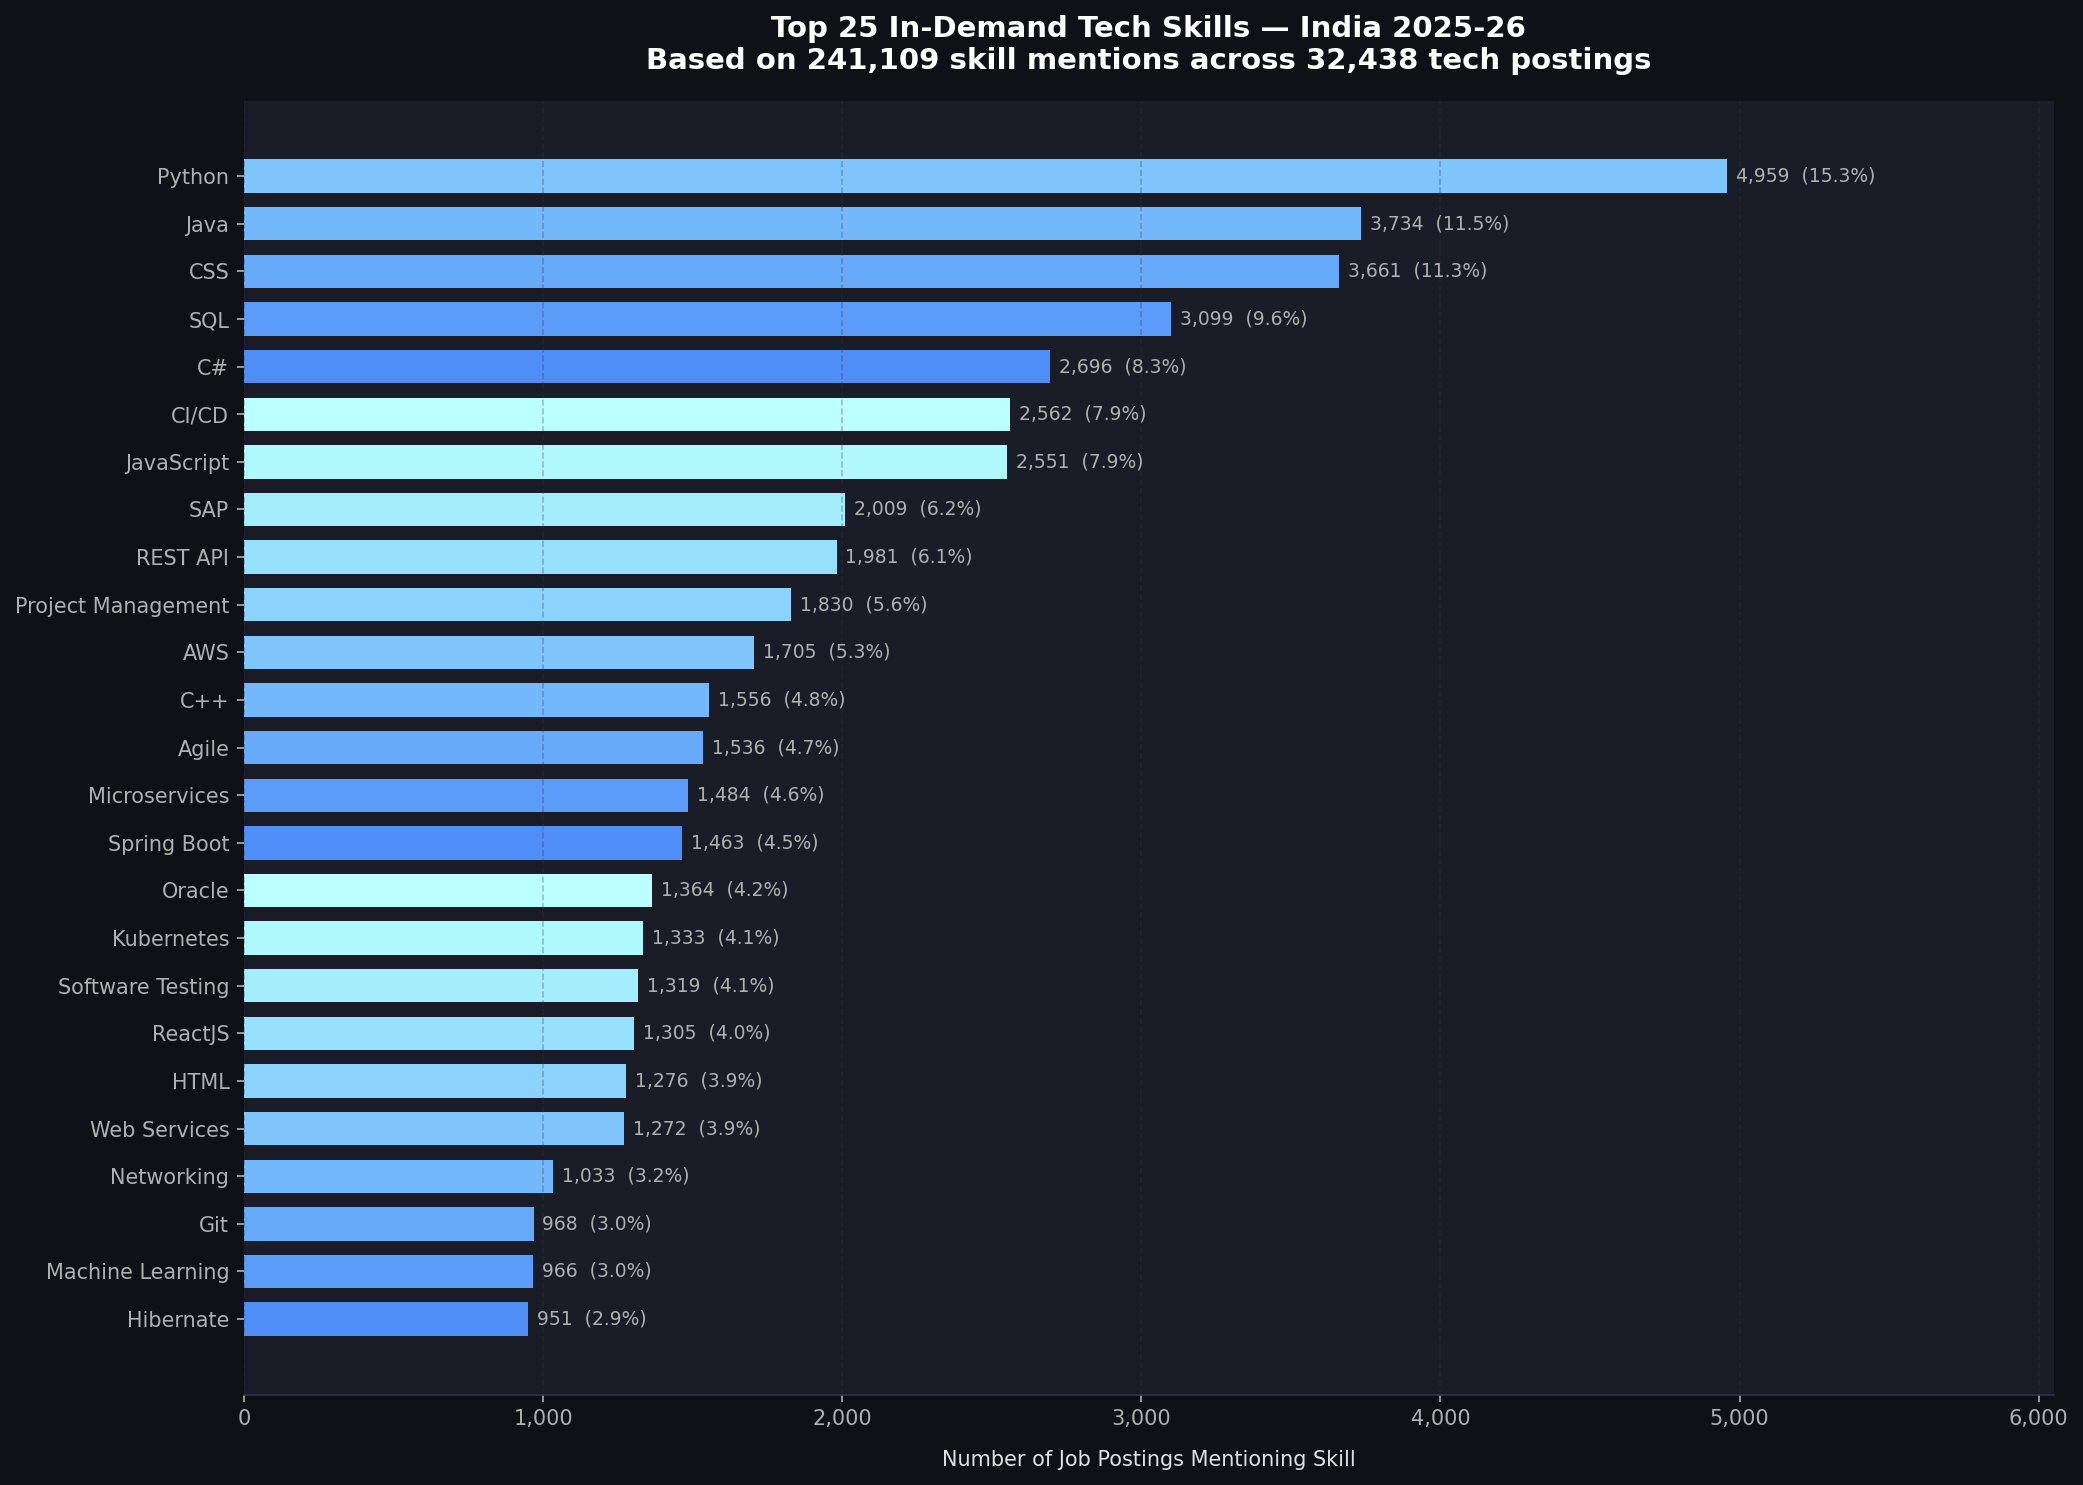

✅ Saved: outputs/charts/A1_top25_skills_demand.png


In [8]:
# ── BLOCK A: SKILL INTELLIGENCE ──────────────────────────────

# ── Chart A1: Top 25 In-Demand Tech Skills ───────────────────
top_skills = (df_skills['skill']
              .value_counts()
              .head(25)
              .reset_index())
top_skills.columns = ['skill', 'count']
top_skills['demand_pct'] = (top_skills['count'] / df_tech['jobId'].nunique() * 100).round(1)

fig, ax = plt.subplots(figsize=(14, 10))

bars = ax.barh(top_skills['skill'][::-1], 
               top_skills['count'][::-1],
               color=BAR_PALETTE * 3,
               edgecolor='none',
               height=0.7)

# Add value labels
for bar, val, pct in zip(bars, 
                          top_skills['count'][::-1], 
                          top_skills['demand_pct'][::-1]):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({pct}%)',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])
ax.set_xlabel('Number of Job Postings Mentioning Skill', labelpad=10)
ax.set_title('Top 25 In-Demand Tech Skills — India 2025-26\n'
             f'Based on {len(df_skills):,} skill mentions across {df_tech.shape[0]:,} tech postings',
             pad=15)
ax.set_xlim(0, top_skills['count'].max() * 1.22)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('A1_top25_skills_demand.png')

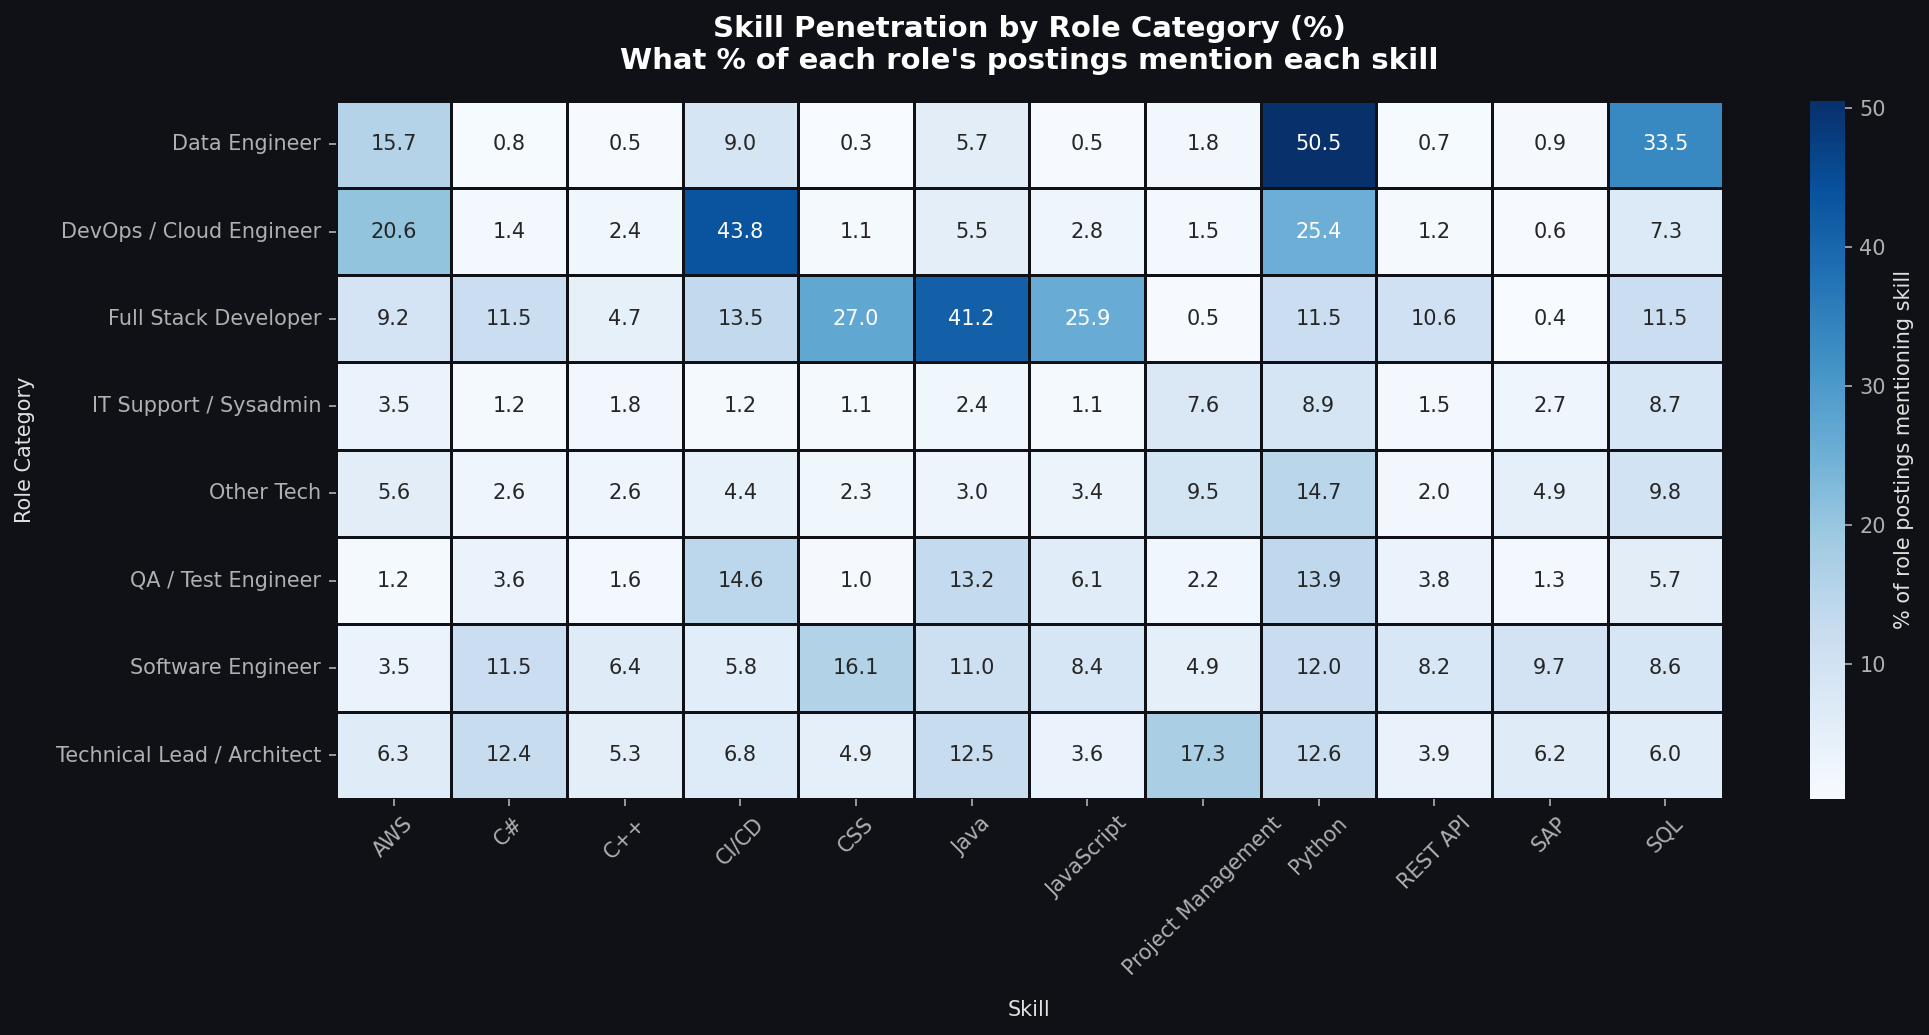

✅ Saved: outputs/charts/A2_skill_penetration_heatmap.png


In [9]:
# ── Chart A2: Top Skills by Role Category (Heatmap) ──────────
# Which skills dominate in which role?

top10_skills = df_skills['skill'].value_counts().head(12).index.tolist()
top8_roles = df_tech['role_category'].value_counts().head(8).index.tolist()

# Filter to top skills and top roles
df_heat = df_skills[
    df_skills['skill'].isin(top10_skills) & 
    df_skills['role_category'].isin(top8_roles)
].copy()

# Build pivot: skill vs role, value = count of mentions
heat_pivot = (df_heat.groupby(['role_category', 'skill'])
              .size()
              .unstack(fill_value=0))

# Normalize by row (each role's total postings) to get % of role that mentions skill
role_totals = df_tech[df_tech['role_category'].isin(top8_roles)]['role_category'].value_counts()
heat_pct = heat_pivot.div(role_totals, axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(heat_pct.round(1),
            annot=True, fmt='.1f',
            cmap='Blues',
            linewidths=0.5,
            linecolor='#0F1117',
            ax=ax,
            cbar_kws={'label': '% of role postings mentioning skill'})

ax.set_title('Skill Penetration by Role Category (%)\n'
             'What % of each role\'s postings mention each skill',
             pad=15)
ax.set_xlabel('Skill', labelpad=10)
ax.set_ylabel('Role Category', labelpad=10)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
save_chart('A2_skill_penetration_heatmap.png')

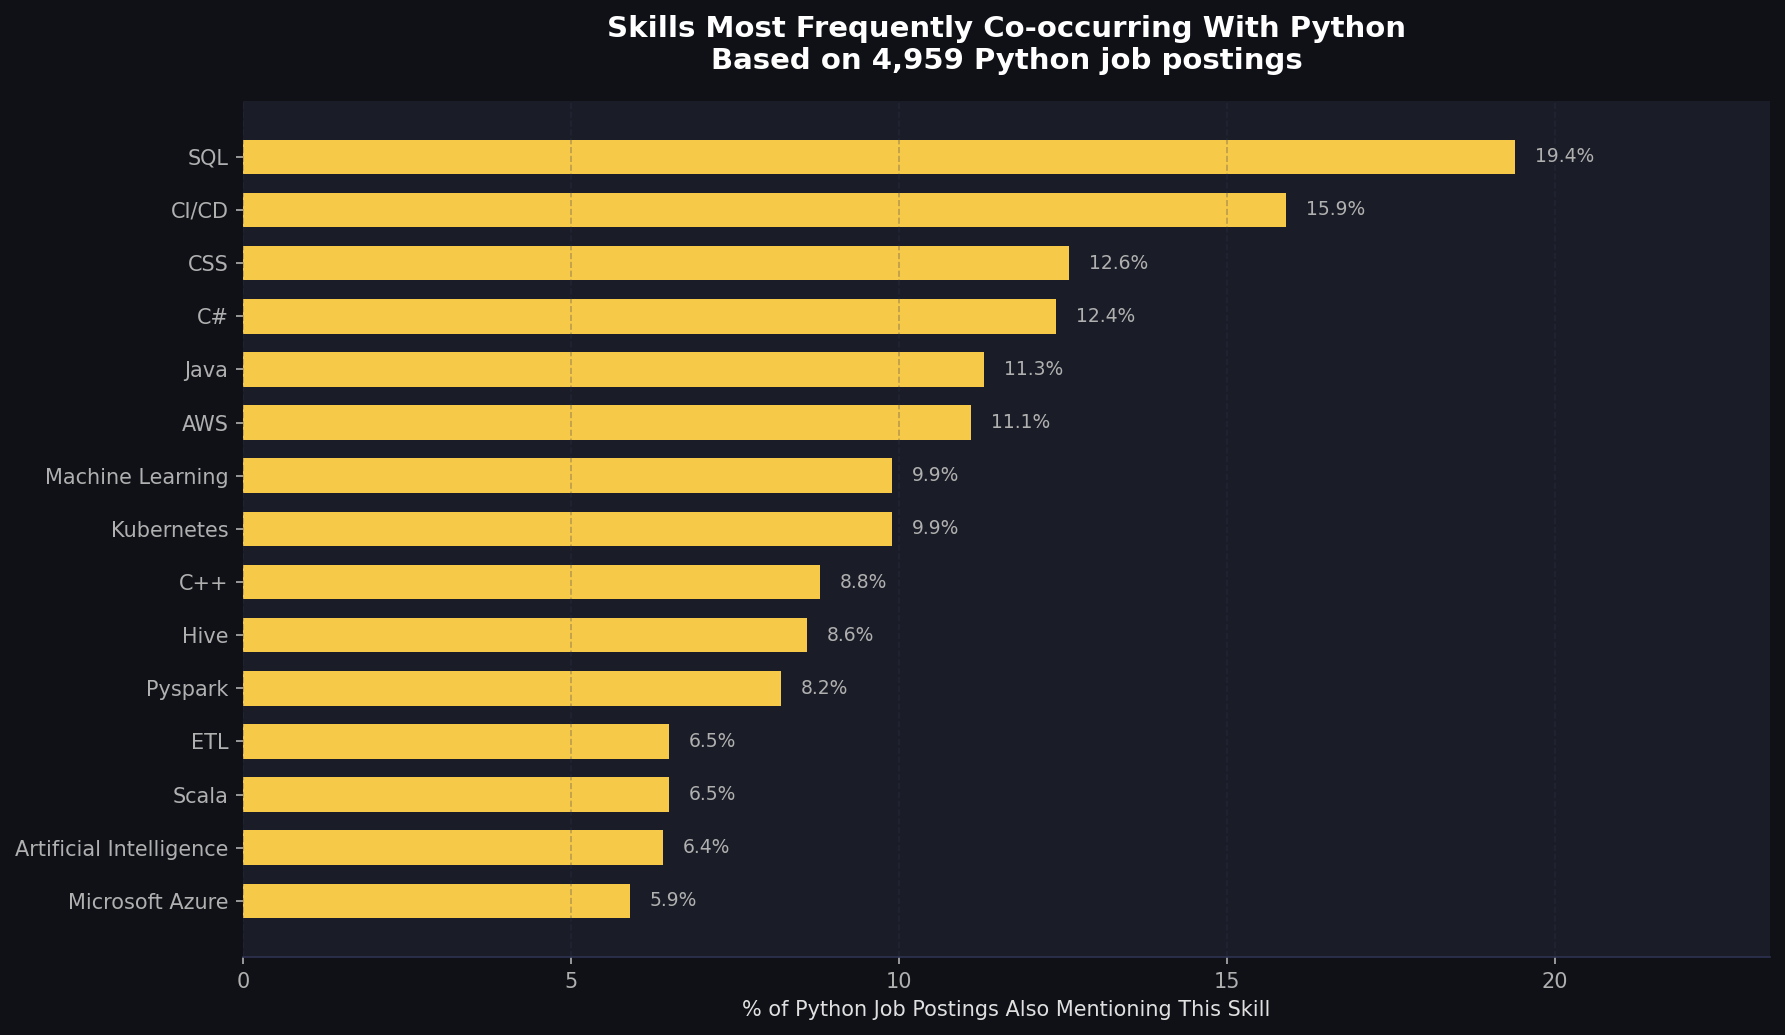

✅ Saved: outputs/charts/A3_python_skill_cooccurrence.png


In [10]:
# ── Chart A3: Skills Co-occurrence — What Appears With Python? ─
# Business Question 5: Which skills appear together most often?

python_jobs = df_skills[df_skills['skill'] == 'Python']['jobId'].unique()

co_skills = (df_skills[
    df_skills['jobId'].isin(python_jobs) & 
    (df_skills['skill'] != 'Python')
]['skill']
.value_counts()
.head(15)
.reset_index())
co_skills.columns = ['skill', 'count']
co_skills['pct_of_python_jobs'] = (co_skills['count'] / len(python_jobs) * 100).round(1)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(co_skills['skill'][::-1],
               co_skills['pct_of_python_jobs'][::-1],
               color=COLORS['secondary'],
               edgecolor='none',
               height=0.65)

for bar, pct in zip(bars, co_skills['pct_of_python_jobs'][::-1]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{pct}%', va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.set_xlabel('% of Python Job Postings Also Mentioning This Skill')
ax.set_title('Skills Most Frequently Co-occurring With Python\n'
             f'Based on {len(python_jobs):,} Python job postings',
             pad=15)
ax.set_xlim(0, co_skills['pct_of_python_jobs'].max() * 1.2)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('A3_python_skill_cooccurrence.png')

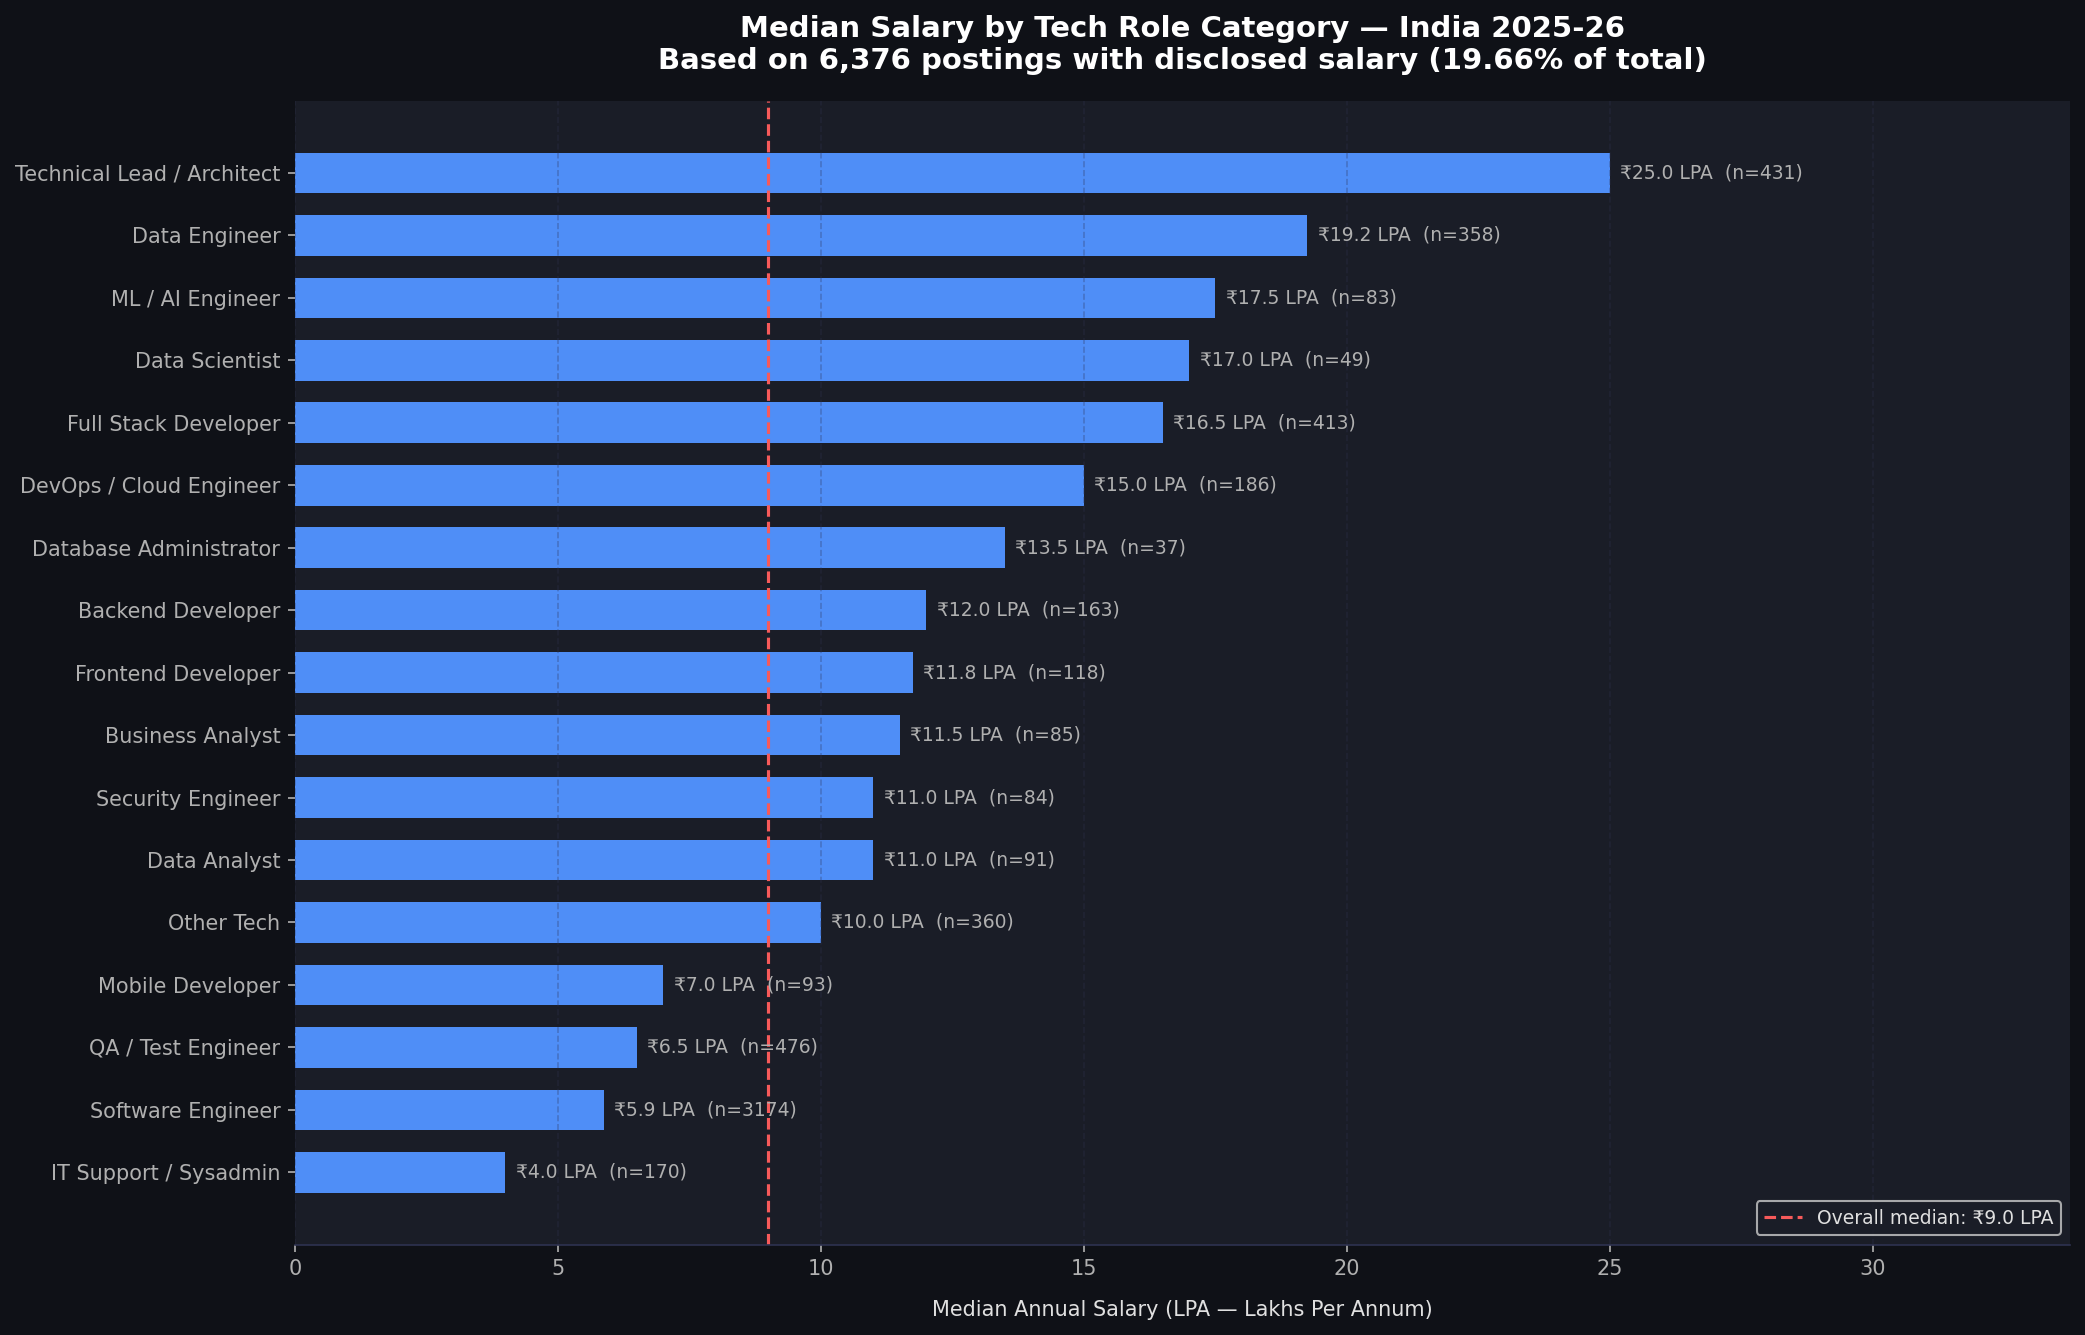

✅ Saved: outputs/charts/B1_salary_by_role.png


In [11]:
# ── BLOCK B: SALARY INTELLIGENCE ─────────────────────────────

# ── Chart B1: Salary Distribution by Role Category ───────────
top_roles_salary = (df_salary.groupby('role_category')['salary_lpa']
                    .agg(['median', 'mean', 'count'])
                    .reset_index()
                    .rename(columns={'median': 'median_lpa', 
                                     'mean': 'mean_lpa',
                                     'count': 'n_postings'})
                    .query('n_postings >= 30')  # min 30 postings for statistical reliability
                    .sort_values('median_lpa', ascending=True))

fig, ax = plt.subplots(figsize=(14, 9))

bars = ax.barh(top_roles_salary['role_category'],
               top_roles_salary['median_lpa'],
               color=COLORS['primary'],
               edgecolor='none',
               height=0.65)

# Add median value + sample size labels
for bar, row in zip(bars, top_roles_salary.itertuples()):
    ax.text(bar.get_width() + 0.2,
            bar.get_y() + bar.get_height()/2,
            f'₹{row.median_lpa:.1f} LPA  (n={row.n_postings})',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.axvline(df_salary['salary_lpa'].median(), 
           color=COLORS['accent'], 
           linestyle='--', linewidth=1.5,
           label=f'Overall median: ₹{df_salary["salary_lpa"].median():.1f} LPA')

ax.set_xlabel('Median Annual Salary (LPA — Lakhs Per Annum)', labelpad=10)
ax.set_title('Median Salary by Tech Role Category — India 2025-26\n'
             f'Based on {len(df_salary):,} postings with disclosed salary (19.66% of total)',
             pad=15)
ax.set_xlim(0, top_roles_salary['median_lpa'].max() * 1.35)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('B1_salary_by_role.png')

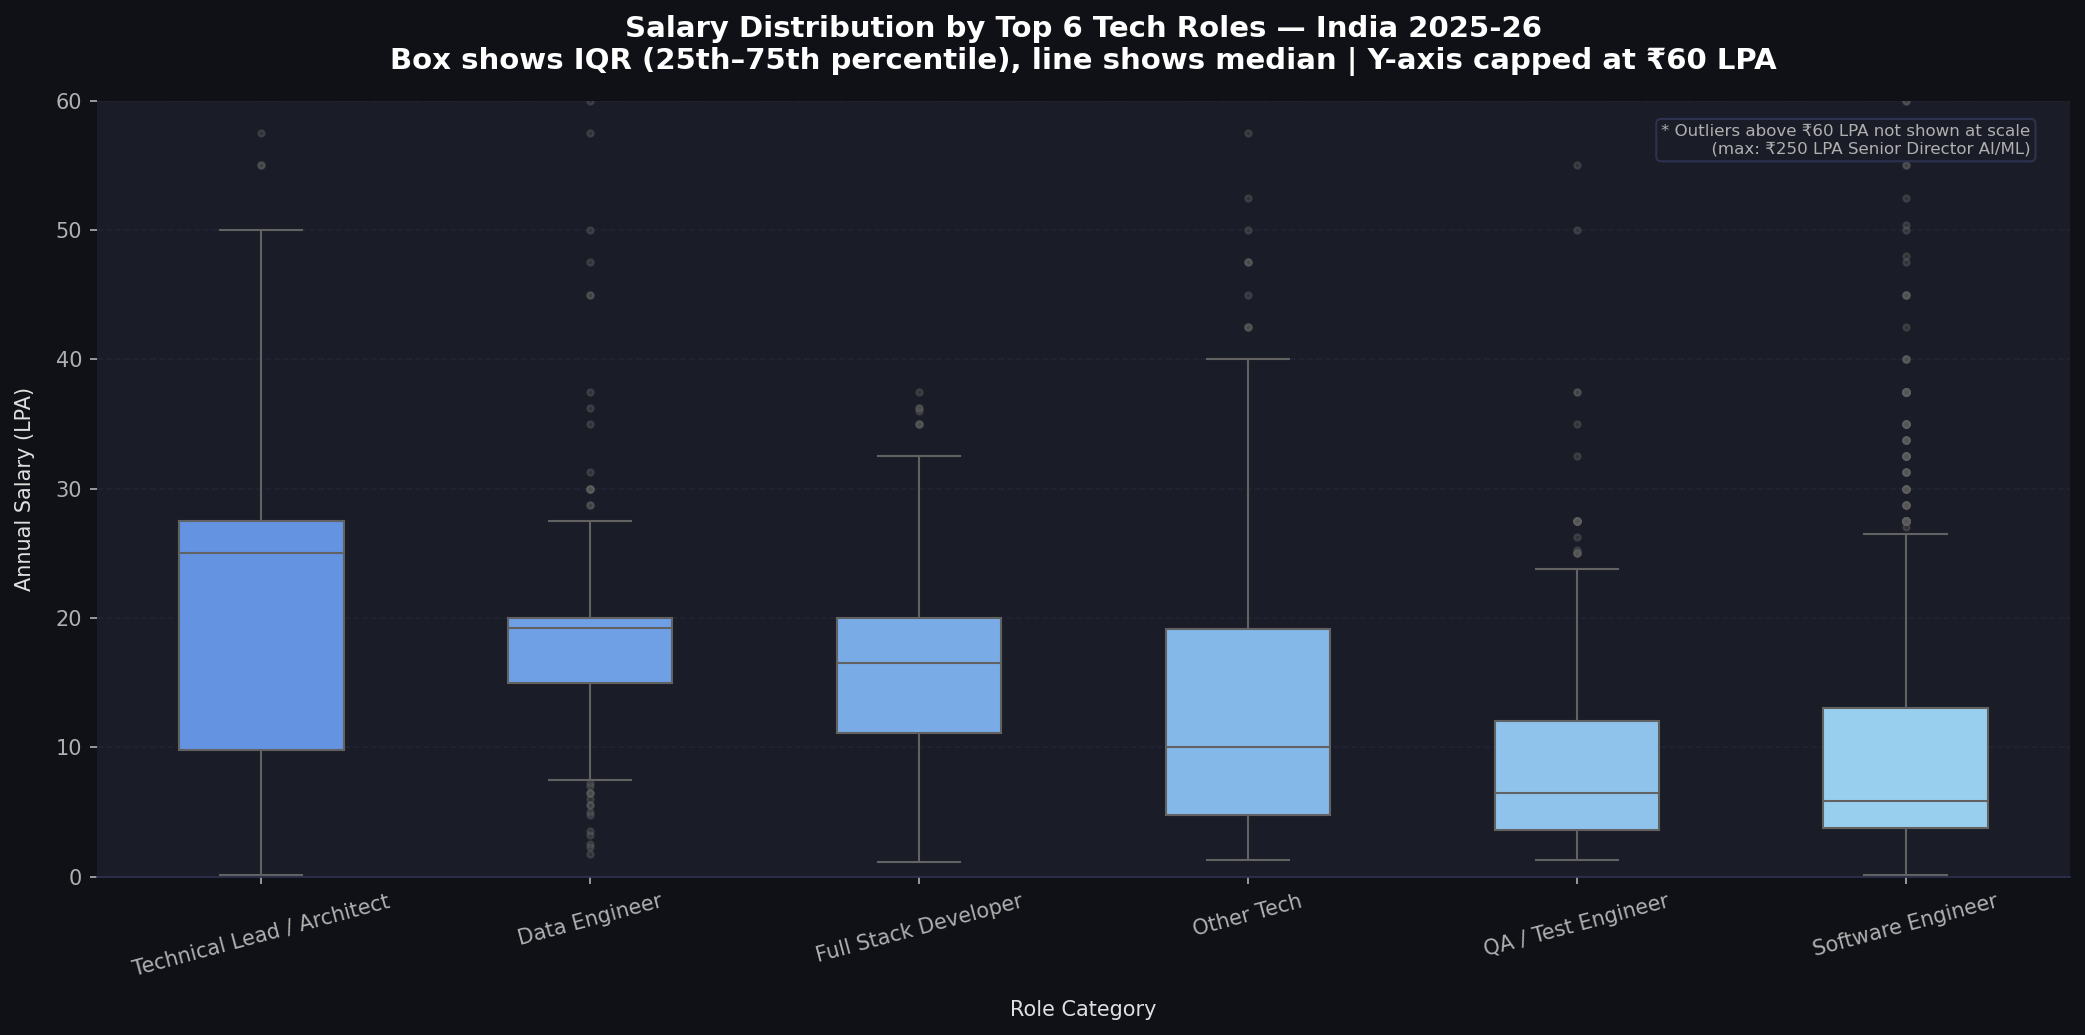

✅ Saved: outputs/charts/B2_salary_distribution_boxplot.png


In [12]:
# ── Chart B2 Fixed: Cap Y-axis to show distribution clearly ──
top6_roles = (df_salary.groupby('role_category')['salary_lpa']
              .count()
              .nlargest(6)
              .index.tolist())

df_b2 = df_salary[df_salary['role_category'].isin(top6_roles)].copy()

order = (df_b2.groupby('role_category')['salary_lpa']
         .median()
         .sort_values(ascending=False)
         .index.tolist())

fig, ax = plt.subplots(figsize=(14, 7))

bp = sns.boxplot(data=df_b2,
                 x='role_category',
                 y='salary_lpa',
                 order=order,
                 palette=BAR_PALETTE[:6],
                 width=0.5,
                 flierprops=dict(marker='o', markerfacecolor='#555',
                                 markersize=3, alpha=0.4),
                 ax=ax)

# Cap Y-axis — outliers still shown as dots above the cap
ax.set_ylim(0, 60)
ax.annotate('* Outliers above ₹60 LPA not shown at scale\n'
            '  (max: ₹250 LPA Senior Director AI/ML)',
            xy=(0.98, 0.97), xycoords='axes fraction',
            ha='right', va='top', fontsize=8,
            color=COLORS['subtext'],
            bbox=dict(boxstyle='round,pad=0.3', 
                      facecolor='#1A1D27', edgecolor='#2E3250'))

ax.set_xlabel('Role Category', labelpad=10)
ax.set_ylabel('Annual Salary (LPA)', labelpad=10)
ax.set_title('Salary Distribution by Top 6 Tech Roles — India 2025-26\n'
             'Box shows IQR (25th–75th percentile), line shows median | Y-axis capped at ₹60 LPA',
             pad=15)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('B2_salary_distribution_boxplot.png')

In [13]:
# Re-define overall_median if kernel was restarted
overall_median = df_salary['salary_lpa'].median()
print(f"Overall median salary: ₹{overall_median:.2f} LPA")

Overall median salary: ₹9.00 LPA


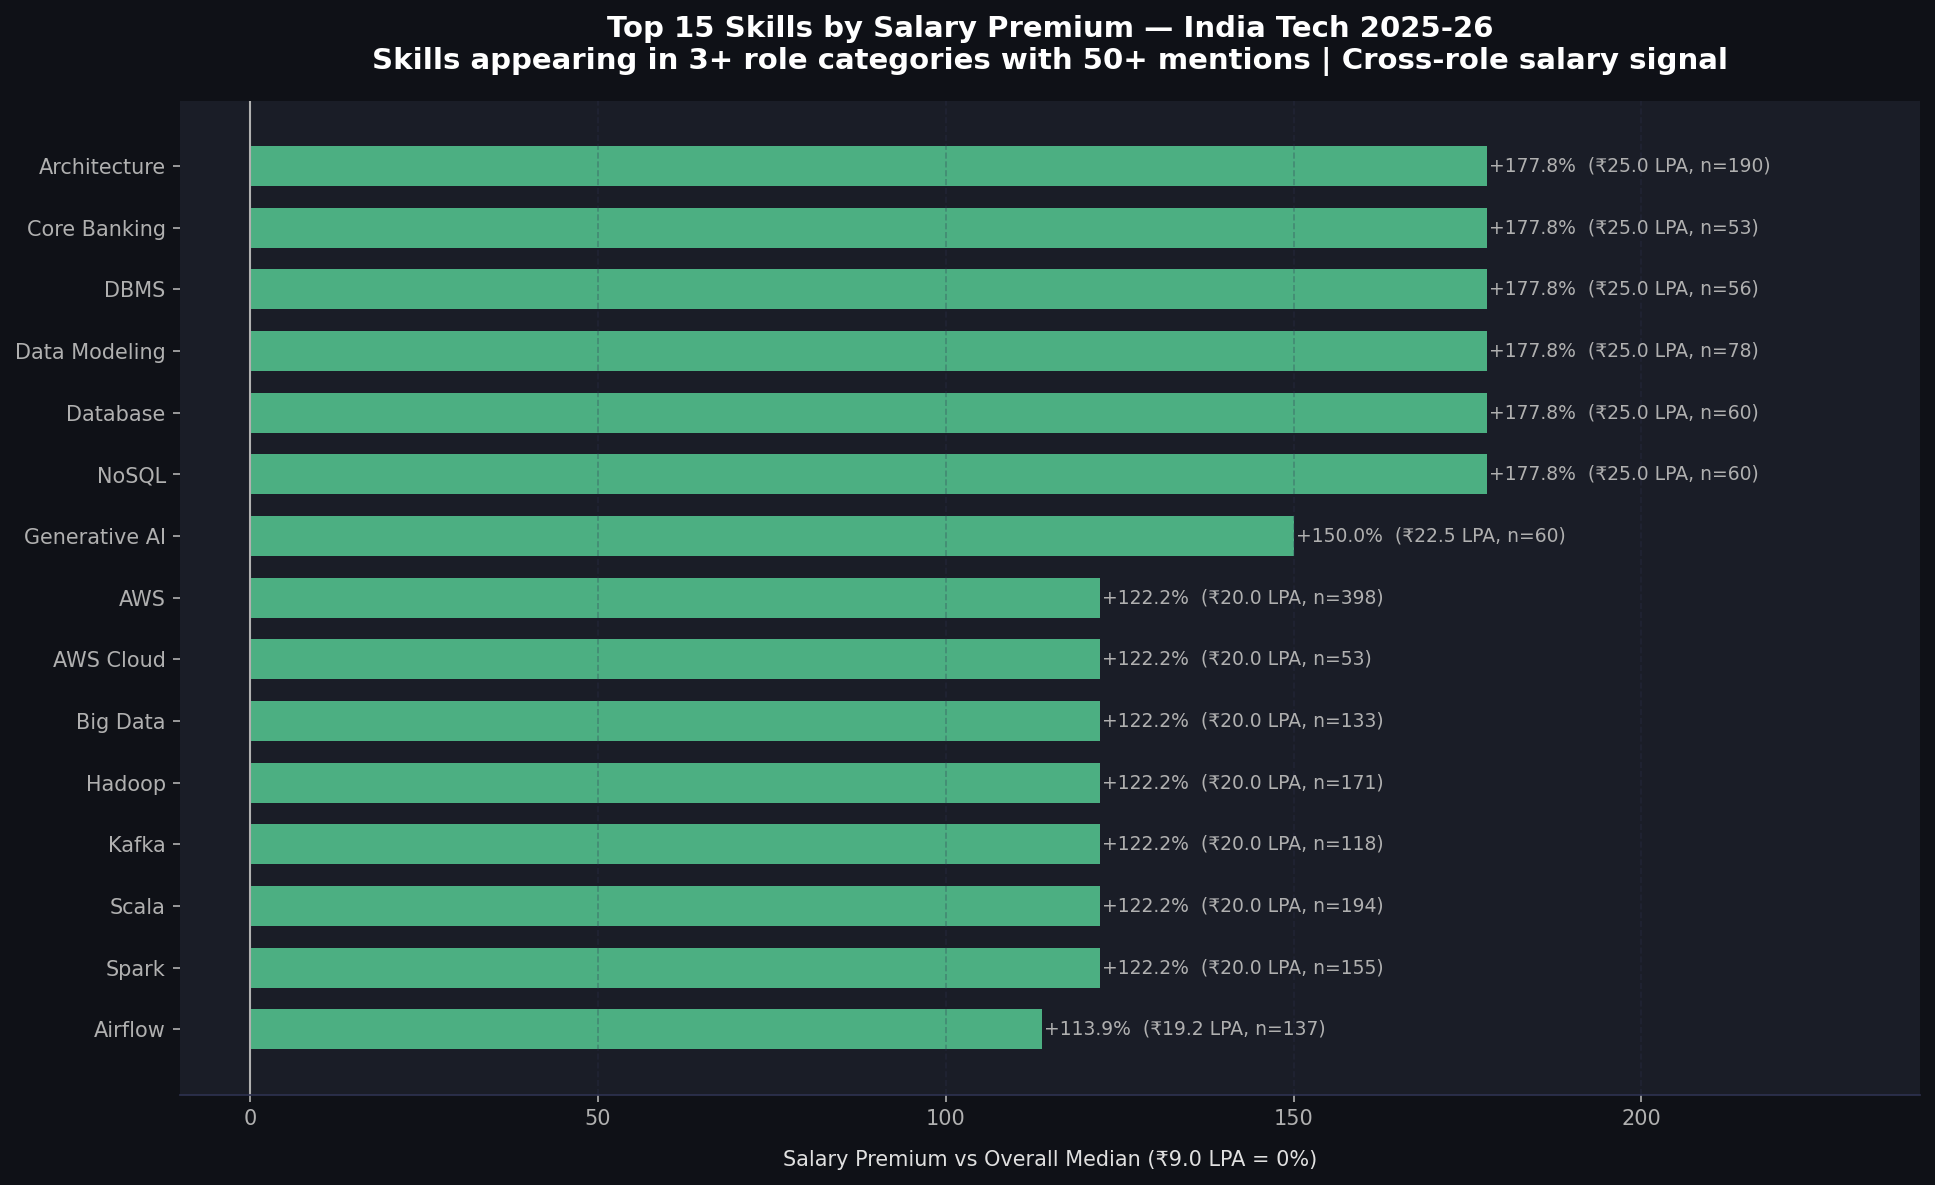

✅ Saved: outputs/charts/B3_skill_salary_premium.png


In [14]:
# Fix 1: Add missing normalizations
additional_normalizations = {
    'Dbms': 'DBMS',
    'Nosql': 'NoSQL',
    'Generative Ai': 'Generative AI',
    'Aws Cloud': 'AWS Cloud',
    'Big Data Engineer': 'Big Data',  # merge with Big Data
    'Core': 'Core Java',             # too generic otherwise
}
df_skills['skill'] = df_skills['skill'].replace(additional_normalizations)

# Fix 2: Exclude skills that are just proxies for the Technical Lead role
# by filtering to skills that appear across AT LEAST 3 different role categories
skill_role_diversity = (df_skills[df_skills['salary_lpa'] > 0]
                        .groupby('skill')['role_category']
                        .nunique()
                        .reset_index()
                        .rename(columns={'role_category': 'n_roles'}))

skill_salary_v2 = (df_skills[df_skills['salary_lpa'] > 0]
                   .groupby('skill')['salary_lpa']
                   .agg(['median', 'count'])
                   .reset_index()
                   .rename(columns={'median': 'median_lpa', 'count': 'n'}))
skill_salary_v2 = skill_salary_v2.merge(skill_role_diversity, on='skill')

# Only skills with 50+ mentions AND appearing in 3+ role categories
skill_salary_v2 = skill_salary_v2[
    (skill_salary_v2['n'] >= 50) & 
    (skill_salary_v2['n_roles'] >= 3)
].copy()

skill_salary_v2['premium_pct'] = (
    (skill_salary_v2['median_lpa'] - overall_median) / overall_median * 100
).round(1)

top_premium_v2 = skill_salary_v2.nlargest(15, 'premium_pct')

fig, ax = plt.subplots(figsize=(13, 8))

colors_v2 = [COLORS['green'] if p > 0 else COLORS['accent']
             for p in top_premium_v2['premium_pct']]

bars = ax.barh(top_premium_v2['skill'][::-1],
               top_premium_v2['premium_pct'][::-1],
               color=colors_v2[::-1],
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, top_premium_v2[::-1].itertuples()):
    ax.text(bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            f'+{row.premium_pct:.1f}%  (₹{row.median_lpa:.1f} LPA, n={row.n})',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.axvline(0, color=COLORS['subtext'], linewidth=1)
ax.set_xlabel('Salary Premium vs Overall Median (₹9.0 LPA = 0%)', labelpad=10)
ax.set_title('Top 15 Skills by Salary Premium — India Tech 2025-26\n'
             'Skills appearing in 3+ role categories with 50+ mentions | Cross-role salary signal',
             pad=15)
ax.set_xlim(-10, top_premium_v2['premium_pct'].max() * 1.35)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('B3_skill_salary_premium.png')

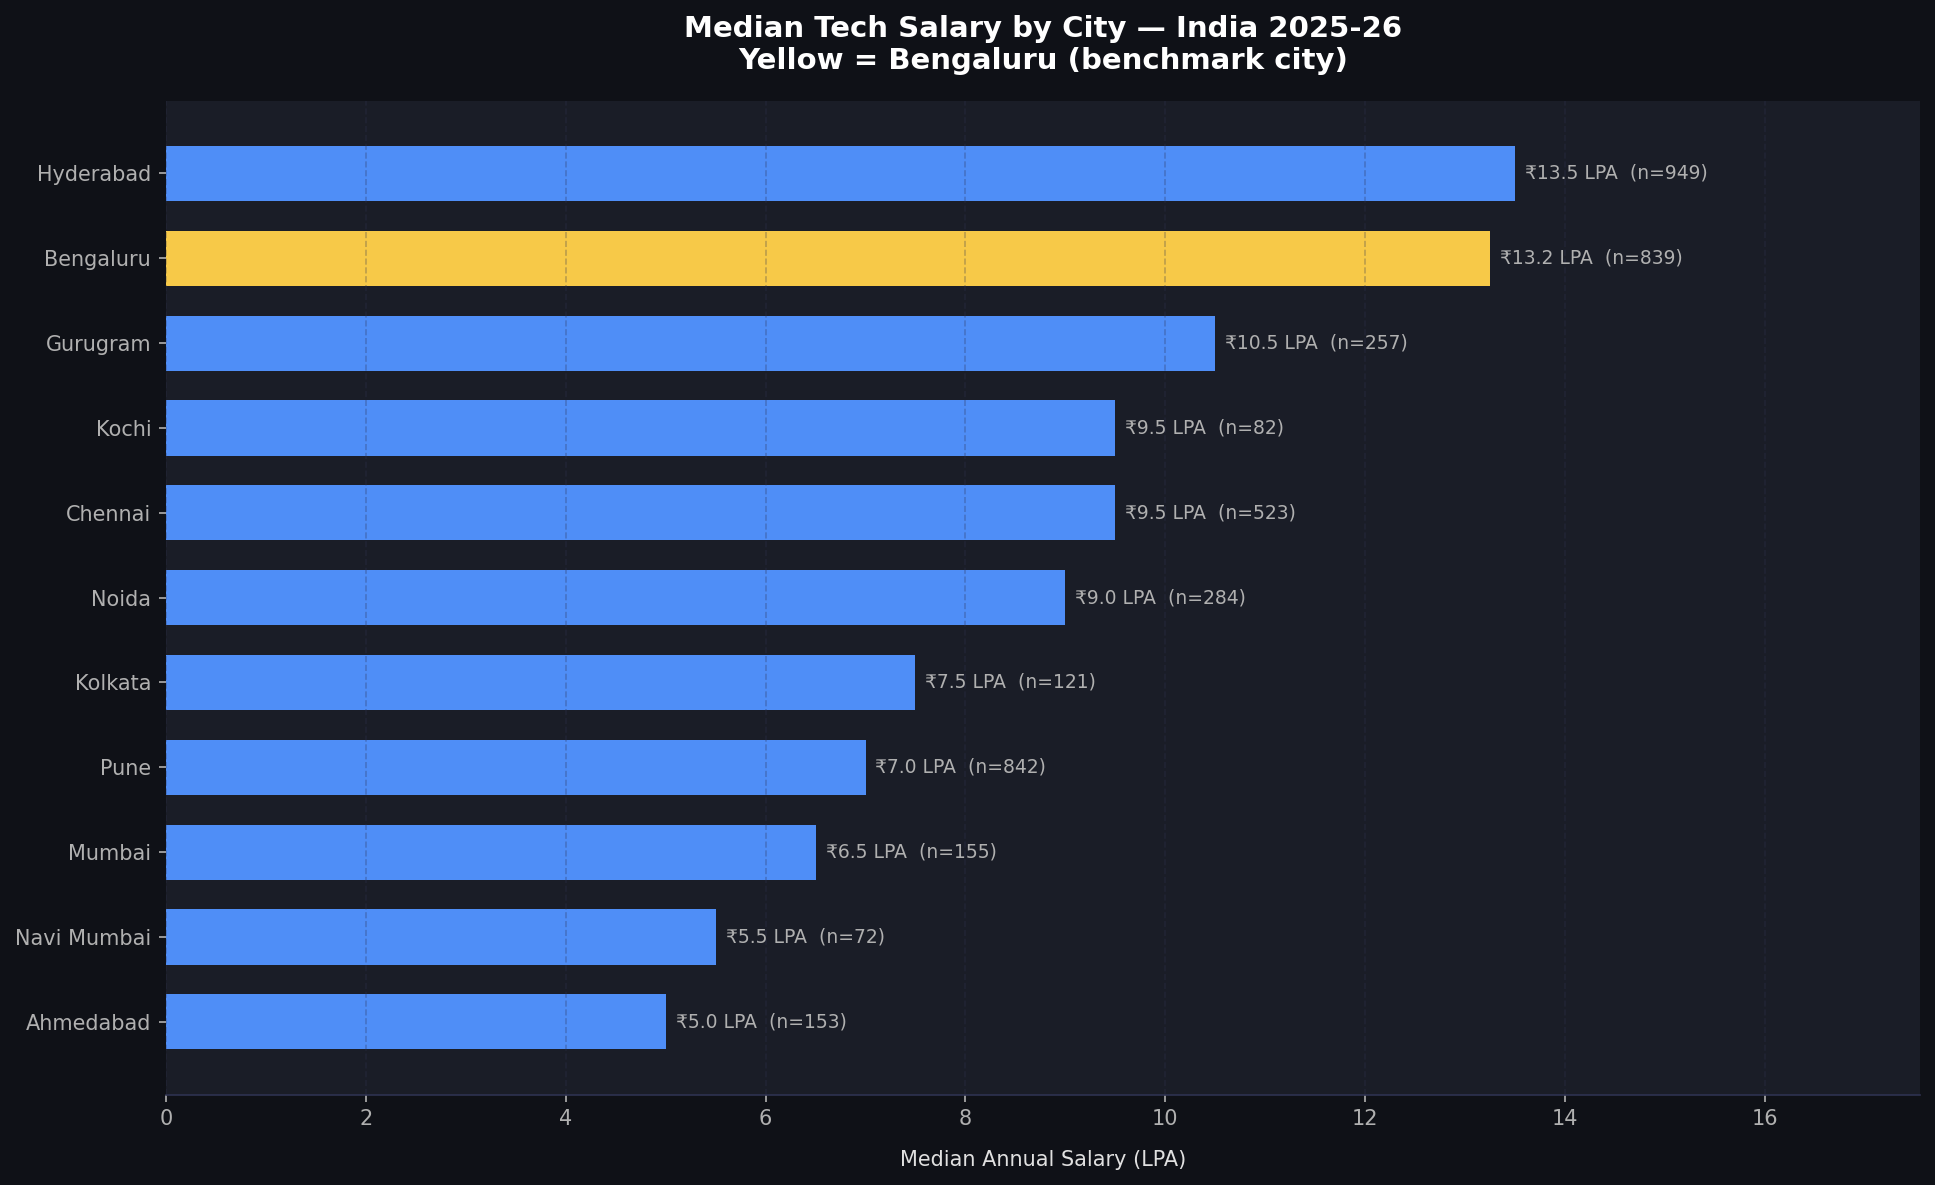

✅ Saved: outputs/charts/B4_salary_by_city.png


In [15]:
# ── Chart B4: Salary by City (Top 12 Cities) ─────────────────
top12_cities = (df_salary.groupby('city_tier_group')['salary_lpa']
                .count()
                .nlargest(13)
                .index.tolist())

# Remove "Other Cities" and "Not Specified"
top12_cities = [c for c in top12_cities 
                if c not in ['Other Cities', 'Not Specified']][:12]

city_salary = (df_salary[df_salary['city_tier_group'].isin(top12_cities)]
               .groupby('city_tier_group')['salary_lpa']
               .agg(['median', 'count'])
               .reset_index()
               .rename(columns={'median': 'median_lpa', 'count': 'n'})
               .sort_values('median_lpa', ascending=True))

fig, ax = plt.subplots(figsize=(13, 8))

bar_colors = [COLORS['secondary'] if city == 'Bengaluru' 
              else COLORS['primary'] for city in city_salary['city_tier_group']]

bars = ax.barh(city_salary['city_tier_group'],
               city_salary['median_lpa'],
               color=bar_colors,
               edgecolor='none',
               height=0.65)
for bar, row in zip(bars, city_salary.itertuples()):
    ax.text(bar.get_width() + 0.1,
            bar.get_y() + bar.get_height()/2,
            f'₹{row.median_lpa:.1f} LPA  (n={row.n})',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.set_xlabel('Median Annual Salary (LPA)', labelpad=10)
ax.set_title('Median Tech Salary by City — India 2025-26\n'
             'Yellow = Bengaluru (benchmark city)',
             pad=15)
ax.set_xlim(0, city_salary['median_lpa'].max() * 1.3)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('B4_salary_by_city.png')

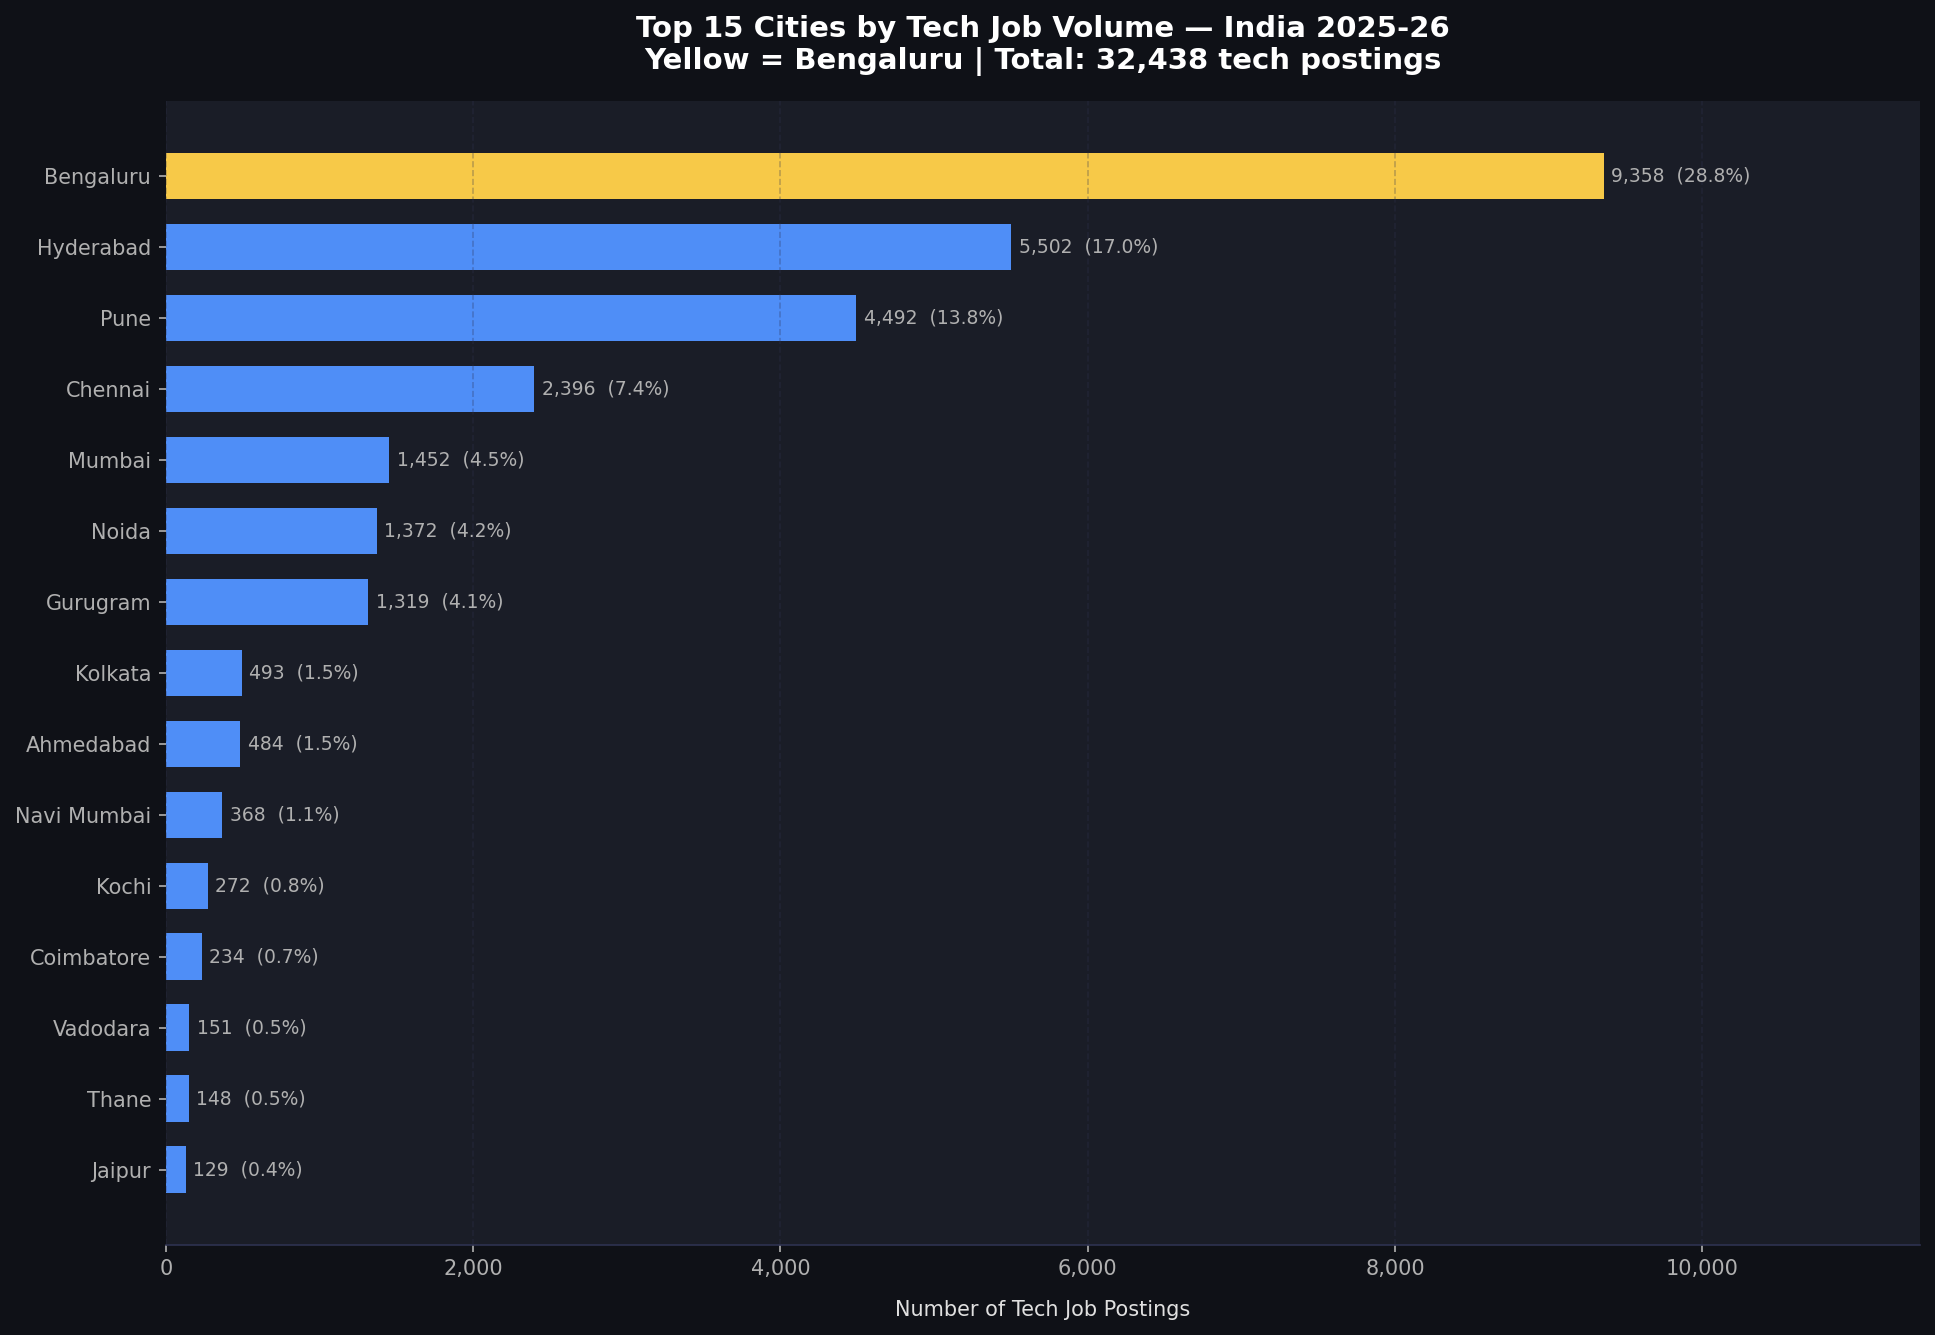

✅ Saved: outputs/charts/C1_city_job_volume.png


In [16]:
# ── BLOCK C: LOCATION INTELLIGENCE ───────────────────────────

# ── Chart C1: Top 15 Cities by Tech Job Volume ───────────────
city_volume = (df_tech[~df_tech['city_tier_group']
               .isin(['Other Cities', 'Not Specified', 
                      'International/Remote', 'Unspecified'])]
               .groupby('city_tier_group')
               .size()
               .reset_index(name='job_count')
               .sort_values('job_count', ascending=True)
               .tail(15))

fig, ax = plt.subplots(figsize=(13, 9))

bar_colors = [COLORS['secondary'] if c == 'Bengaluru' 
              else COLORS['primary'] for c in city_volume['city_tier_group']]

bars = ax.barh(city_volume['city_tier_group'],
               city_volume['job_count'],
               color=bar_colors,
               edgecolor='none',
               height=0.65)

for bar, val in zip(bars, city_volume['job_count']):
    pct = val / len(df_tech) * 100
    ax.text(bar.get_width() + 50,
            bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({pct:.1f}%)',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.set_xlabel('Number of Tech Job Postings', labelpad=10)
ax.set_title('Top 15 Cities by Tech Job Volume — India 2025-26\n'
             f'Yellow = Bengaluru | Total: {len(df_tech):,} tech postings',
             pad=15)
ax.set_xlim(0, city_volume['job_count'].max() * 1.22)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('C1_city_job_volume.png')

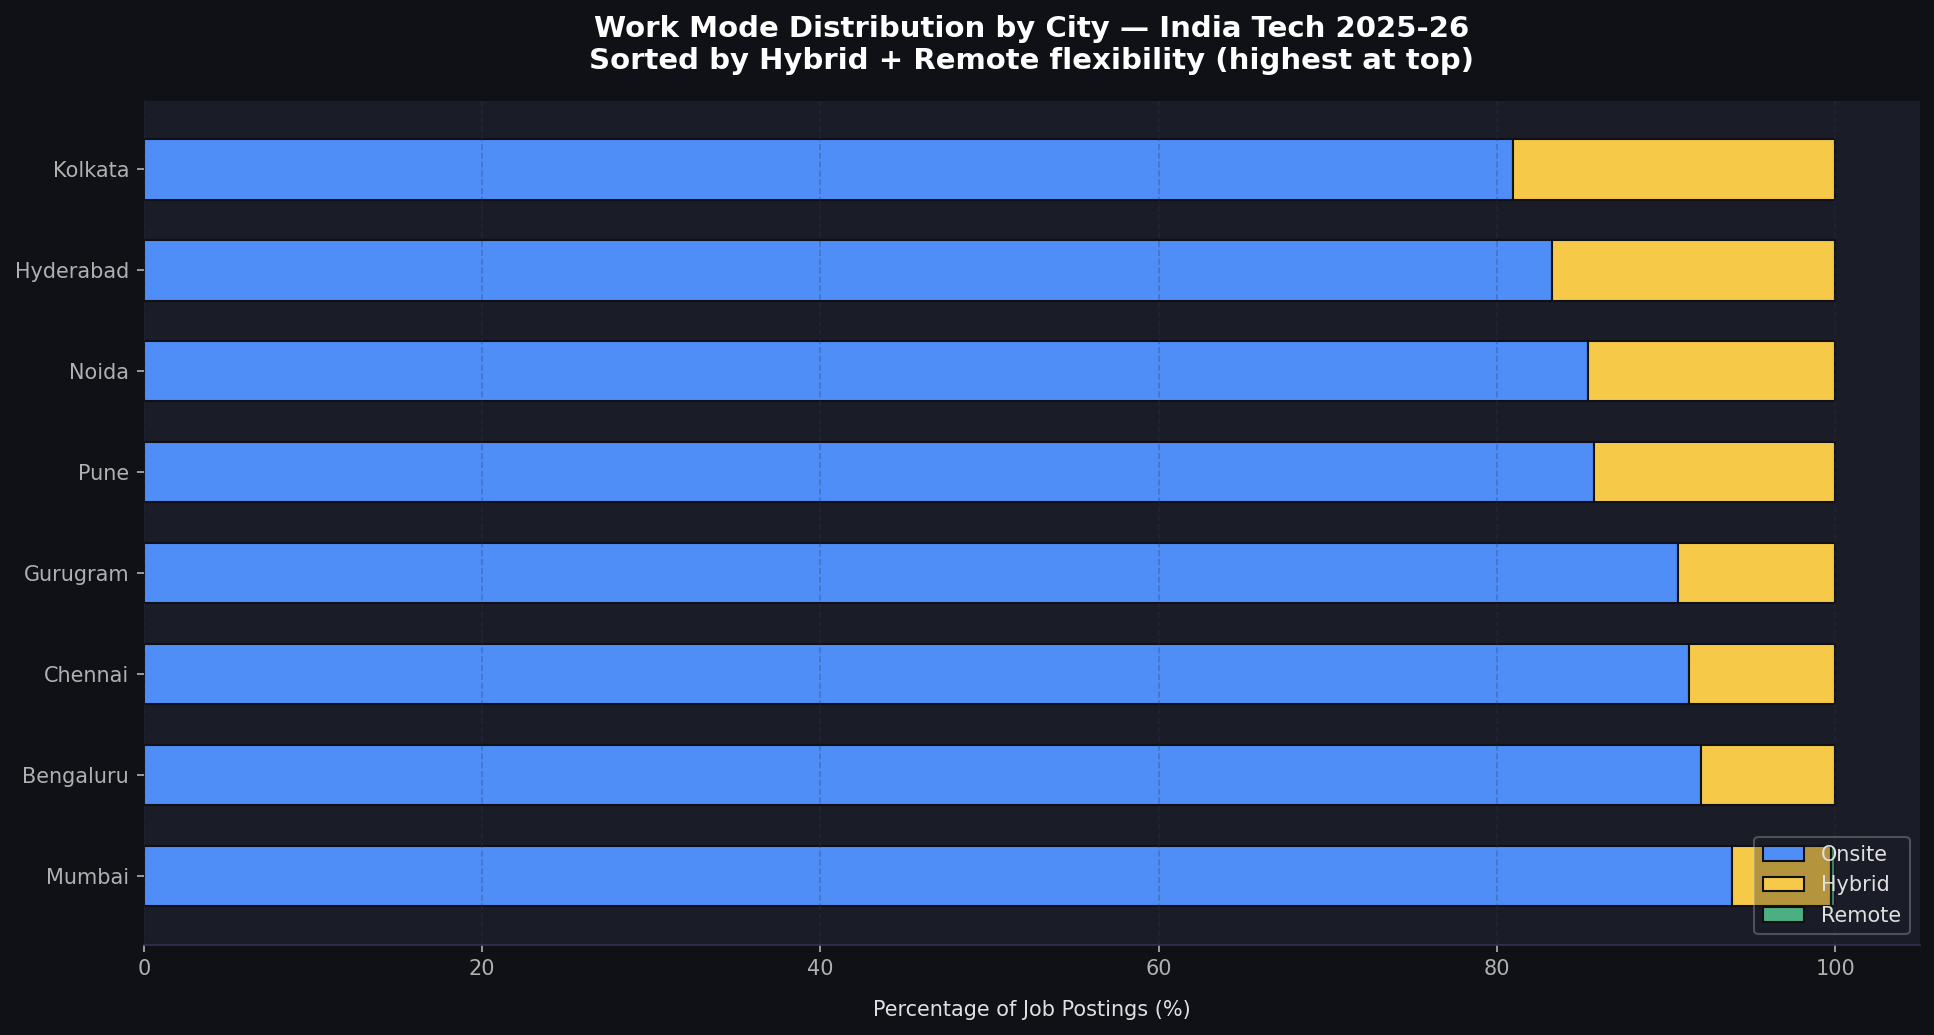

✅ Saved: outputs/charts/C2_work_mode_by_city.png


In [17]:
# ── Chart C2: Work Mode Distribution by City ─────────────────
top8_cities = (df_tech[~df_tech['city_tier_group']
               .isin(['Other Cities', 'Not Specified',
                      'International/Remote', 'Unspecified'])]
               .groupby('city_tier_group')
               .size()
               .nlargest(8)
               .index.tolist())

work_mode_city = (df_tech[df_tech['city_tier_group'].isin(top8_cities)]
                  .groupby(['city_tier_group', 'work_mode'])
                  .size()
                  .unstack(fill_value=0))

# Convert to percentages
work_mode_pct = work_mode_city.div(work_mode_city.sum(axis=1), axis=0) * 100

# Sort by hybrid+remote percentage
work_mode_pct['flexible'] = (work_mode_pct.get('Hybrid', 0) + 
                              work_mode_pct.get('Remote', 0))
work_mode_pct = work_mode_pct.sort_values('flexible', ascending=True)
work_mode_pct = work_mode_pct.drop('flexible', axis=1)

colors_wm = {'Onsite': COLORS['primary'], 
             'Hybrid': COLORS['secondary'], 
             'Remote': COLORS['green']}

fig, ax = plt.subplots(figsize=(13, 7))

left = pd.Series([0.0] * len(work_mode_pct), index=work_mode_pct.index)
for mode in ['Onsite', 'Hybrid', 'Remote']:
    if mode in work_mode_pct.columns:
        ax.barh(work_mode_pct.index,
                work_mode_pct[mode],
                left=left,
                color=colors_wm[mode],
                label=mode,
                edgecolor='#0F1117',
                height=0.6)
        left += work_mode_pct[mode]

ax.set_xlabel('Percentage of Job Postings (%)', labelpad=10)
ax.set_title('Work Mode Distribution by City — India Tech 2025-26\n'
             'Sorted by Hybrid + Remote flexibility (highest at top)',
             pad=15)
ax.legend(loc='lower right', framealpha=0.3)
ax.set_xlim(0, 105)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('C2_work_mode_by_city.png')

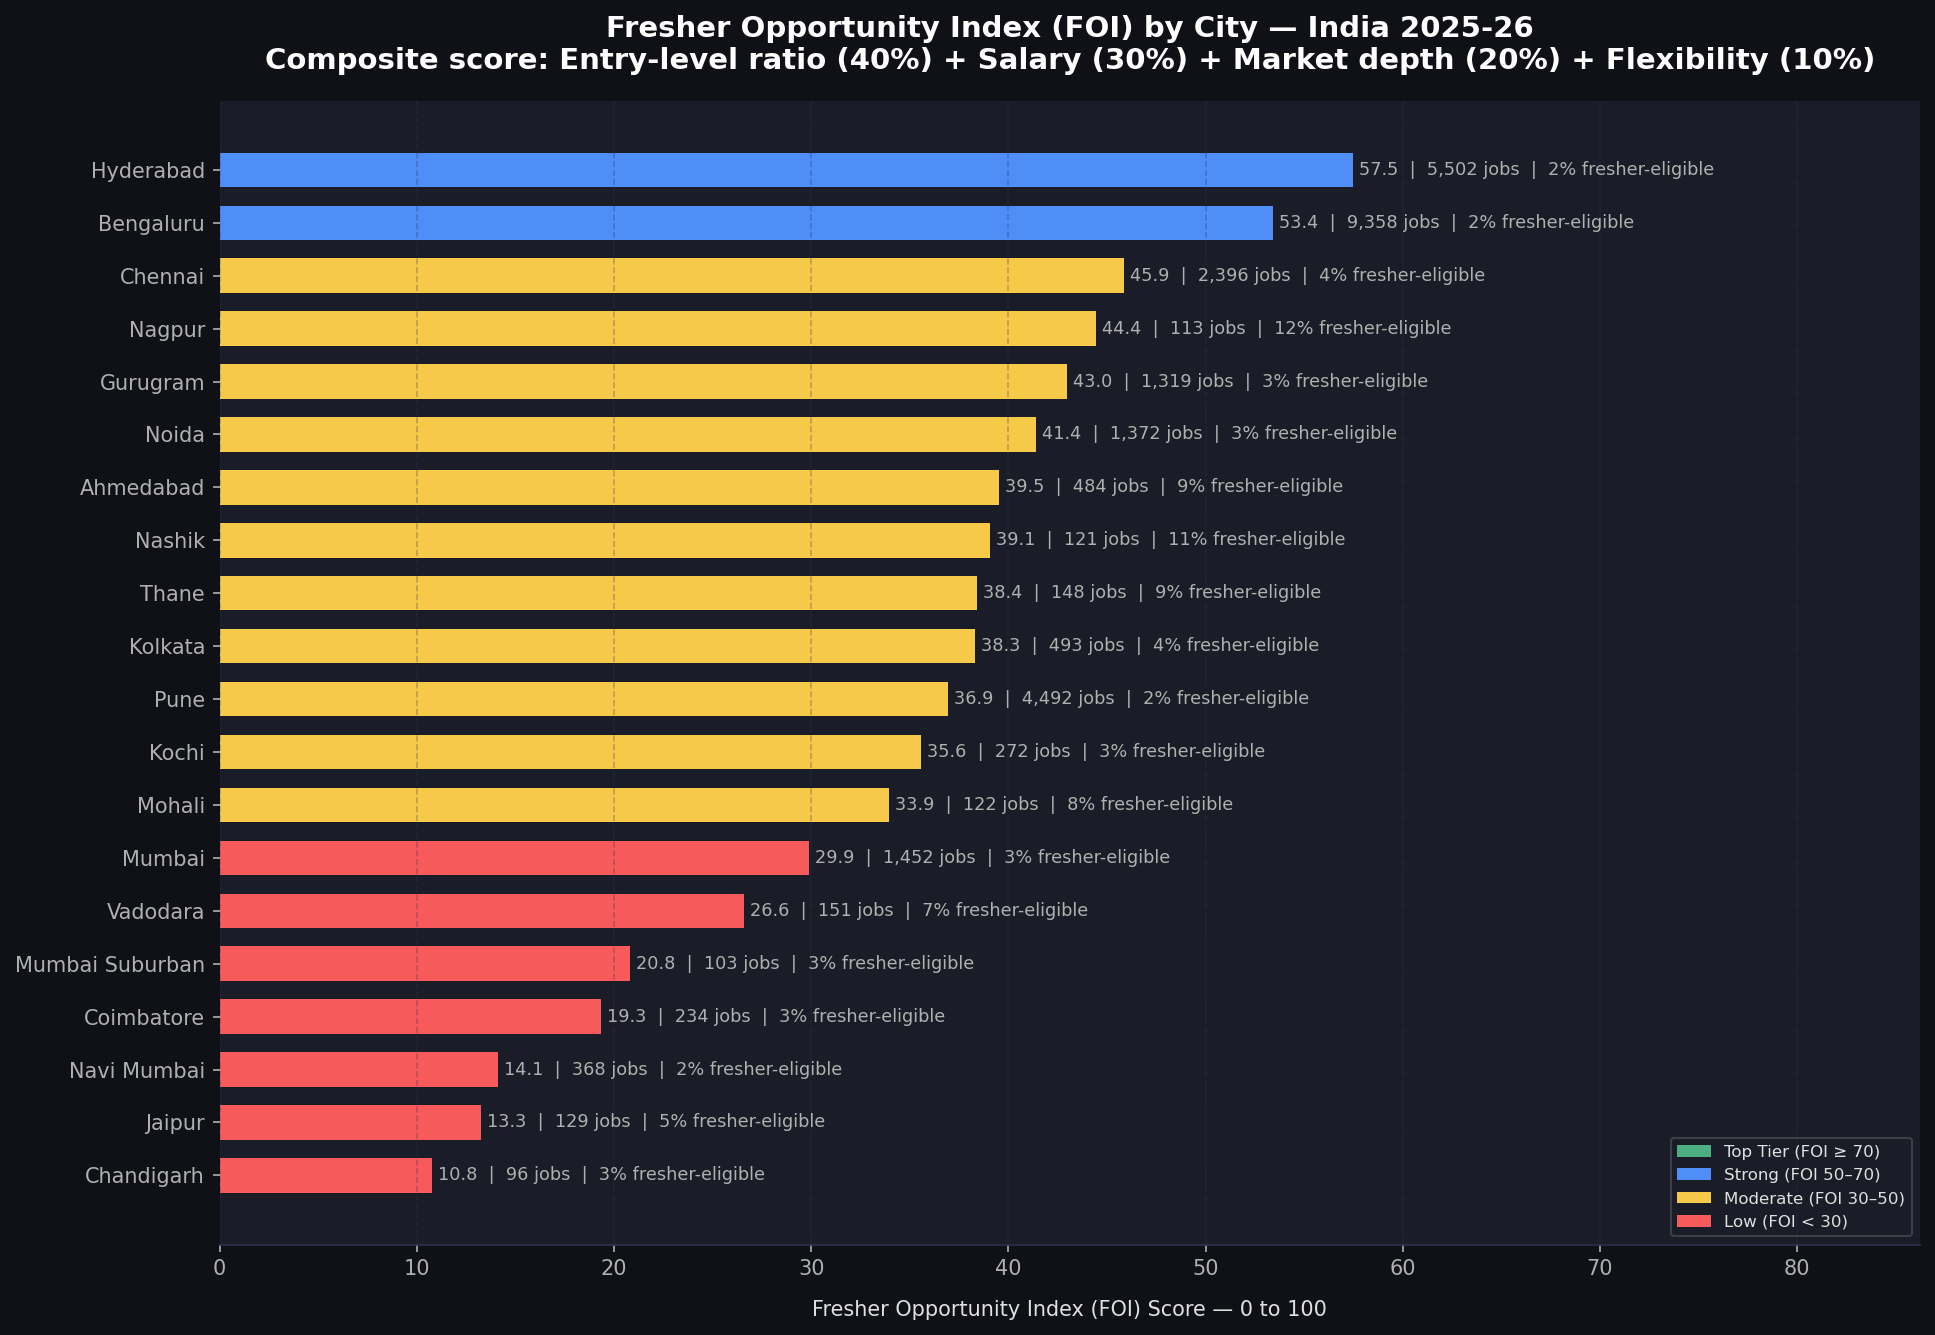

✅ Saved: outputs/charts/C3_fresher_opportunity_index.png

FOI Rankings:
           city  FOI_score  total_postings  fresher_ratio  city_median_lpa
      Hyderabad       57.5            5502            2.0          13.5000
      Bengaluru       53.4            9358            1.7          13.2500
        Chennai       45.9            2396            4.3           9.5000
         Nagpur       44.4             113           12.4           4.0000
       Gurugram       43.0            1319            3.3          10.5000
          Noida       41.4            1372            3.3           9.0000
      Ahmedabad       39.5             484            8.7           5.0000
         Nashik       39.1             121           10.7           4.5000
          Thane       38.4             148            8.8           6.6250
        Kolkata       38.3             493            4.3           7.5000
           Pune       36.9            4492            2.4           7.0000
          Kochi       35.6  

In [19]:
# ── Chart C3: Fresher Opportunity Index (FOI) ────────────────
# Your SIGNATURE metric — the one that makes this project unique

# FOI Components per city:
# 1. Entry-level posting ratio (40% weight)  = % of postings where minimumExperience == 0
# 2. Salary competitiveness (30% weight)     = city median salary / national median salary
# 3. Job market depth (20% weight)           = log-normalized posting volume
# 4. Work flexibility (10% weight)           = % hybrid + remote postings

target_cities = (df_tech[~df_tech['city_tier_group']
                 .isin(['Other Cities', 'Not Specified',
                        'International/Remote', 'Unspecified'])]
                 .groupby('city_tier_group')
                 .size()
                 .nlargest(20)
                 .index.tolist())

foi_data = []
national_median = df_salary['salary_lpa'].median()

for city in target_cities:
    city_df = df_tech[df_tech['city_tier_group'] == city]
    city_salary_df = df_salary[df_salary['city_tier_group'] == city]
    
    total = len(city_df)
    if total < 50:
        continue
    
    # Component 1: Entry-level ratio (minimumExperience == 0)
    fresher_ratio = (city_df['minimumExperience'] == 0).sum() / total
    
    # Component 2: Salary competitiveness vs national median
    if len(city_salary_df) >= 20:
        city_median = city_salary_df['salary_lpa'].median()
        salary_score = min(city_median / national_median, 2.0)  # cap at 2x
    else:
        salary_score = 1.0  # assume average if insufficient data
    
    # Component 3: Job market depth (log-normalized, max city gets score 1.0)
    depth_score = np.log1p(total)
    
    # Component 4: Work flexibility
    flex_ratio = (city_df['work_mode'].isin(['Hybrid', 'Remote'])).sum() / total
    
    foi_data.append({
        'city': city,
        'total_postings': total,
        'fresher_ratio': fresher_ratio,
        'salary_score': salary_score,
        'depth_score': depth_score,
        'flex_ratio': flex_ratio,
        'city_median_lpa': city_salary_df['salary_lpa'].median() 
                           if len(city_salary_df) >= 20 else None
    })

foi_df = pd.DataFrame(foi_data)

# Normalize depth score to 0-1
foi_df['depth_norm'] = (foi_df['depth_score'] - foi_df['depth_score'].min()) / \
                        (foi_df['depth_score'].max() - foi_df['depth_score'].min())

# Normalize salary score to 0-1
foi_df['salary_norm'] = (foi_df['salary_score'] - foi_df['salary_score'].min()) / \
                         (foi_df['salary_score'].max() - foi_df['salary_score'].min())

# Normalize flex ratio to 0-1
foi_df['flex_norm'] = (foi_df['flex_ratio'] - foi_df['flex_ratio'].min()) / \
                       (foi_df['flex_ratio'].max() - foi_df['flex_ratio'].min())

# Normalize fresher ratio to 0-1
foi_df['fresher_norm'] = (foi_df['fresher_ratio'] - foi_df['fresher_ratio'].min()) / \
                          (foi_df['fresher_ratio'].max() - foi_df['fresher_ratio'].min())

# Calculate FOI (weighted composite score, 0-100)
foi_df['FOI_score'] = (
    foi_df['fresher_norm']  * 0.40 +
    foi_df['salary_norm']   * 0.30 +
    foi_df['depth_norm']    * 0.20 +
    foi_df['flex_norm']     * 0.10
) * 100

foi_df = foi_df.sort_values('FOI_score', ascending=True)

# ── Plot FOI ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 9))

# Color bars by tier
def foi_color(score):
    if score >= 70: return '#4CAF82'    # green — top tier
    elif score >= 50: return '#4F8EF7'  # blue  — strong
    elif score >= 30: return '#F7C948'  # yellow — moderate
    else: return '#F75A5A'              # red   — low

bar_colors_foi = [foi_color(s) for s in foi_df['FOI_score']]

bars = ax.barh(foi_df['city'],
               foi_df['FOI_score'],
               color=bar_colors_foi,
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, foi_df.itertuples()):
    label = f'{row.FOI_score:.1f}  |  {row.total_postings:,} jobs  |  {row.fresher_ratio*100:.0f}% fresher-eligible'
    ax.text(bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            label,
            va='center', ha='left', fontsize=8.5, color=COLORS['subtext'])

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF82', label='Top Tier (FOI ≥ 70)'),
    Patch(facecolor='#4F8EF7', label='Strong (FOI 50–70)'),
    Patch(facecolor='#F7C948', label='Moderate (FOI 30–50)'),
    Patch(facecolor='#F75A5A', label='Low (FOI < 30)')
]
ax.legend(handles=legend_elements, loc='lower right', 
          framealpha=0.2, fontsize=8)

ax.set_xlabel('Fresher Opportunity Index (FOI) Score — 0 to 100', labelpad=10)
ax.set_title('Fresher Opportunity Index (FOI) by City — India 2025-26\n'
             'Composite score: Entry-level ratio (40%) + Salary (30%) + Market depth (20%) + Flexibility (10%)',
             pad=15)
ax.set_xlim(0, foi_df['FOI_score'].max() * 1.5)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('C3_fresher_opportunity_index.png')
# Save FOI table
foi_output = foi_df[['city', 'FOI_score', 'total_postings', 
                       'fresher_ratio', 'city_median_lpa']].copy()
foi_output['fresher_ratio'] = (foi_output['fresher_ratio'] * 100).round(1)
foi_output['FOI_score'] = foi_output['FOI_score'].round(1)
foi_output = foi_output.sort_values('FOI_score', ascending=False)
foi_output.to_csv('outputs/tables/city_foi_scores.csv', index=False)
print("\nFOI Rankings:")
print(foi_output.to_string(index=False))

In [20]:
# Verify fresher ratio calculation
print("Fresher-eligible postings (minimumExperience == 0):")
print(f"Total tech postings: {len(df_tech):,}")
print(f"minimumExperience == 0: {(df_tech['minimumExperience'] == 0).sum():,}")
print(f"Overall fresher ratio: {(df_tech['minimumExperience'] == 0).mean()*100:.2f}%")

# Check what values minimumExperience actually has
print(f"\nminimumExperience value distribution:")
print(df_tech['minimumExperience'].value_counts().head(10))

Fresher-eligible postings (minimumExperience == 0):
Total tech postings: 32,438
minimumExperience == 0: 1,126
Overall fresher ratio: 3.47%

minimumExperience value distribution:
minimumExperience
3.0     5902
5.0     5868
2.0     3382
4.0     3319
6.0     2538
8.0     2064
1.0     2048
7.0     1845
15.0    1647
10.0    1221
Name: count, dtype: int64


In [21]:
# Check what 0-2 years captures
fresher_band = df_tech[df_tech['minimumExperience'] <= 2]
print(f"Postings with minimumExperience 0-2 years: {len(fresher_band):,}")
print(f"As % of total tech postings: {len(fresher_band)/len(df_tech)*100:.2f}%")

# Breakdown by minimumExperience value
print(f"\nBreakdown:")
print(df_tech[df_tech['minimumExperience'] <= 2]['minimumExperience'].value_counts().sort_index())

# Add fresher_eligible flag to df_tech
df_tech['fresher_eligible'] = df_tech['minimumExperience'] <= 2

print(f"\nFresher-eligible postings (0-2 yrs): {df_tech['fresher_eligible'].sum():,}")
print(f"Non-fresher postings (3+ yrs):        {(~df_tech['fresher_eligible']).sum():,}")

Postings with minimumExperience 0-2 years: 6,556
As % of total tech postings: 20.21%

Breakdown:
minimumExperience
0.0    1126
1.0    2048
2.0    3382
Name: count, dtype: int64

Fresher-eligible postings (0-2 yrs): 6,556
Non-fresher postings (3+ yrs):        25,882


In [22]:
# FOI recalculation with corrected fresher definition
fresher_ratio = (city_df['minimumExperience'] <= 2).sum() / total

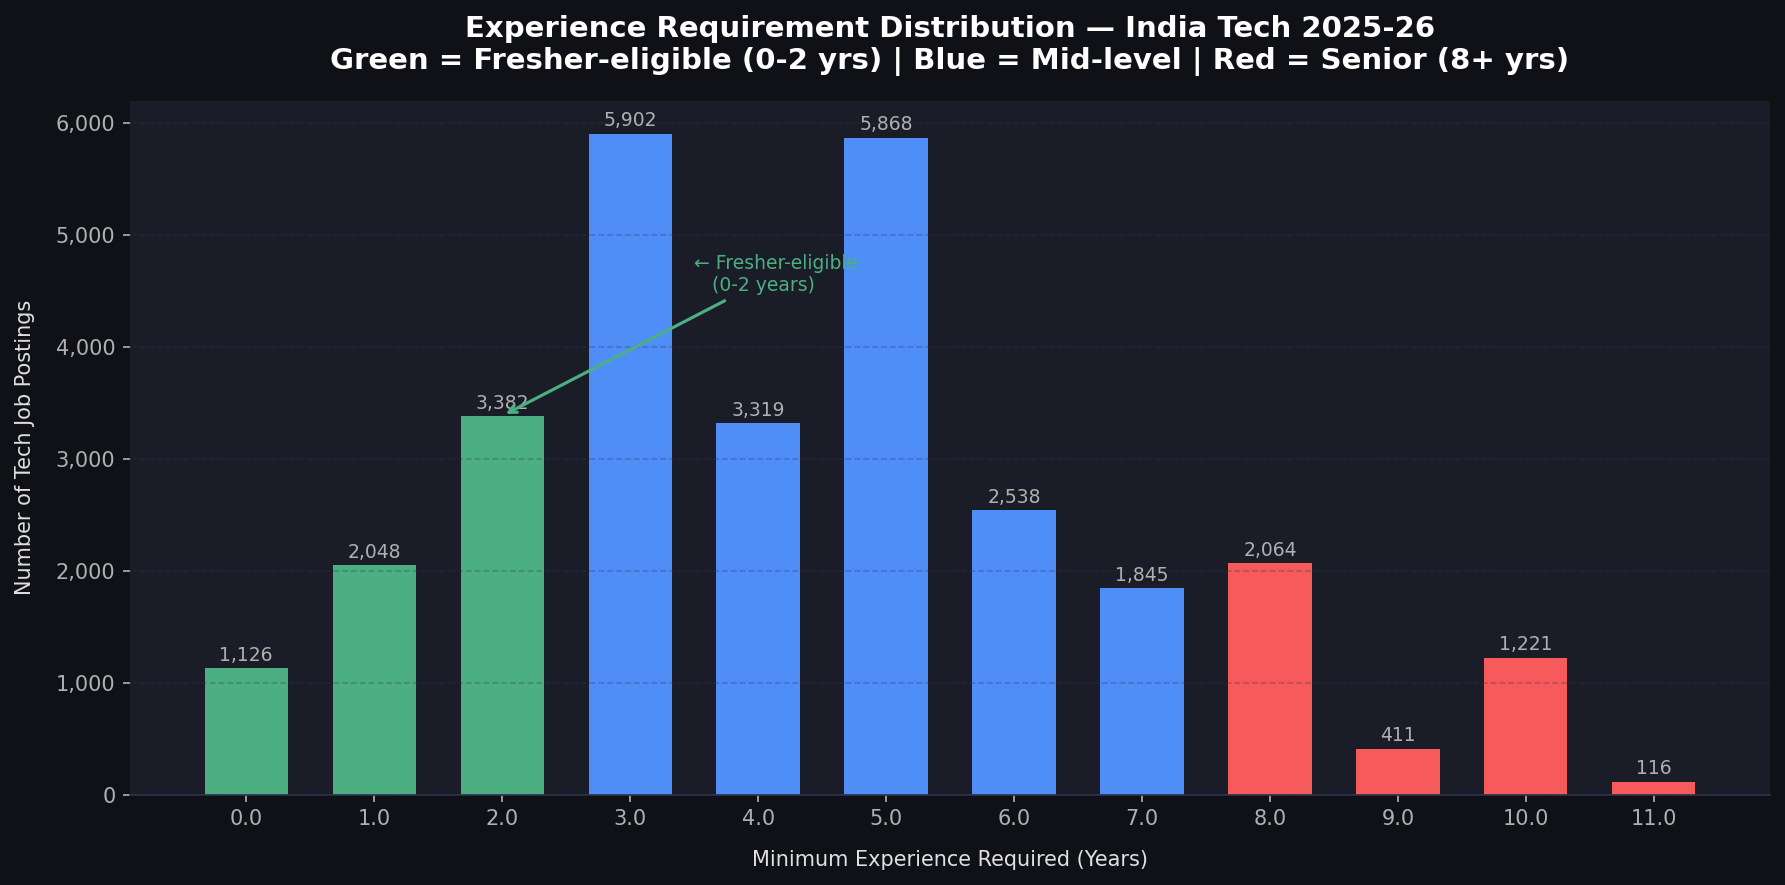

✅ Saved: outputs/charts/C4_experience_requirement_distribution.png


In [23]:
# Quick distribution chart
exp_dist = (df_tech['minimumExperience']
            .value_counts()
            .sort_index()
            .head(12)
            .reset_index())
exp_dist.columns = ['min_experience_years', 'count']

fig, ax = plt.subplots(figsize=(12, 6))

bar_colors = [COLORS['green'] if x <= 2 
              else COLORS['accent'] if x >= 8 
              else COLORS['primary'] 
              for x in exp_dist['min_experience_years']]

bars = ax.bar(exp_dist['min_experience_years'].astype(str),
              exp_dist['count'],
              color=bar_colors,
              edgecolor='none',
              width=0.65)


for bar, val in zip(bars, exp_dist['count']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 30,
            f'{val:,}',
            ha='center', va='bottom', fontsize=9, color=COLORS['subtext'])

# Annotation arrows
ax.annotate('← Fresher-eligible\n   (0-2 years)',
            xy=(2, exp_dist[exp_dist['min_experience_years'] <= 2]['count'].max()),
            xytext=(3.5, 4500),
            color=COLORS['green'],
            fontsize=9,
            arrowprops=dict(arrowstyle='->', color=COLORS['green'], lw=1.5))

ax.set_xlabel('Minimum Experience Required (Years)', labelpad=10)
ax.set_ylabel('Number of Tech Job Postings', labelpad=10)
ax.set_title('Experience Requirement Distribution — India Tech 2025-26\n'
             'Green = Fresher-eligible (0-2 yrs) | Blue = Mid-level | Red = Senior (8+ yrs)',
             pad=15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('C4_experience_requirement_distribution.png')

In [25]:
# ── FOI v2: Corrected fresher definition (0-2 years) ─────────

foi_data_v2 = []
national_median = df_salary['salary_lpa'].median()

target_cities = (df_tech[~df_tech['city_tier_group']
                 .isin(['Other Cities', 'Not Specified',
                        'International/Remote', 'Unspecified'])]
                 .groupby('city_tier_group')
                 .size()
                 .nlargest(20)
                 .index.tolist())

for city in target_cities:
    city_df   = df_tech[df_tech['city_tier_group'] == city]
    city_sal  = df_salary[df_salary['city_tier_group'] == city]
    total     = len(city_df)
    if total < 50:
        continue

    # Component 1: Fresher ratio — CORRECTED to 0-2 years
    fresher_ratio = (city_df['minimumExperience'] <= 2).sum() / total

    # Component 2: Salary competitiveness
    if len(city_sal) >= 20:
        city_median  = city_sal['salary_lpa'].median()
        salary_score = min(city_median / national_median, 2.0)
    else:
        salary_score = 1.0

    # Component 3: Market depth (log-normalized)
    depth_score = np.log1p(total)

    # Component 4: Work flexibility
    flex_ratio = (city_df['work_mode'].isin(['Hybrid', 'Remote'])).sum() / total

    foi_data_v2.append({
        'city'            : city,
        'total_postings'  : total,
        'fresher_ratio'   : round(fresher_ratio * 100, 1),
        'salary_score'    : salary_score,
        'depth_score'     : depth_score,
        'flex_ratio'      : flex_ratio,
        'city_median_lpa' : city_sal['salary_lpa'].median()
                            if len(city_sal) >= 20 else None
    })

foi_v2 = pd.DataFrame(foi_data_v2)

# Normalize all components to 0-1
for col, norm_col in [('fresher_ratio', 'fresher_norm'),
                       ('salary_score',  'salary_norm'),
                       ('depth_score',   'depth_norm'),
                       ('flex_ratio',    'flex_norm')]:
    mn = foi_v2[col].min()
    mx = foi_v2[col].max()
    foi_v2[norm_col] = (foi_v2[col] - mn) / (mx - mn)

# Weighted FOI score
foi_v2['FOI_score'] = (
    foi_v2['fresher_norm'] * 0.40 +
    foi_v2['salary_norm']  * 0.30 +
    foi_v2['depth_norm']   * 0.20 +
    foi_v2['flex_norm']    * 0.10
) * 100

foi_v2 = foi_v2.sort_values('FOI_score', ascending=False).reset_index(drop=True)

print("=" * 75)
print("FRESHER OPPORTUNITY INDEX v2 — FINAL RANKINGS")
print("Definition: fresher-eligible = minimumExperience <= 2 years")
print("=" * 75)
print(foi_v2[['city', 'FOI_score', 'total_postings',
              'fresher_ratio', 'city_median_lpa']].to_string(index=True))

FRESHER OPPORTUNITY INDEX v2 — FINAL RANKINGS
Definition: fresher-eligible = minimumExperience <= 2 years
               city  FOI_score  total_postings  fresher_ratio  city_median_lpa
0         Bengaluru  56.501384            9358           16.9          13.2500
1         Hyderabad  56.473966            5502           14.4          13.5000
2            Mohali  49.638137             122           46.7           6.5000
3          Gurugram  49.529542            1319           24.4          10.5000
4             Thane  48.455256             148           43.9           6.6250
5             Noida  43.450395            1372           20.8           9.0000
6         Ahmedabad  43.410168             484           38.6           5.0000
7           Chennai  42.903312            2396           19.7           9.5000
8             Kochi  41.874501             272           23.2           9.5000
9   Mumbai Suburban  40.561075             103           34.0           7.2500
10             Pune  39.2

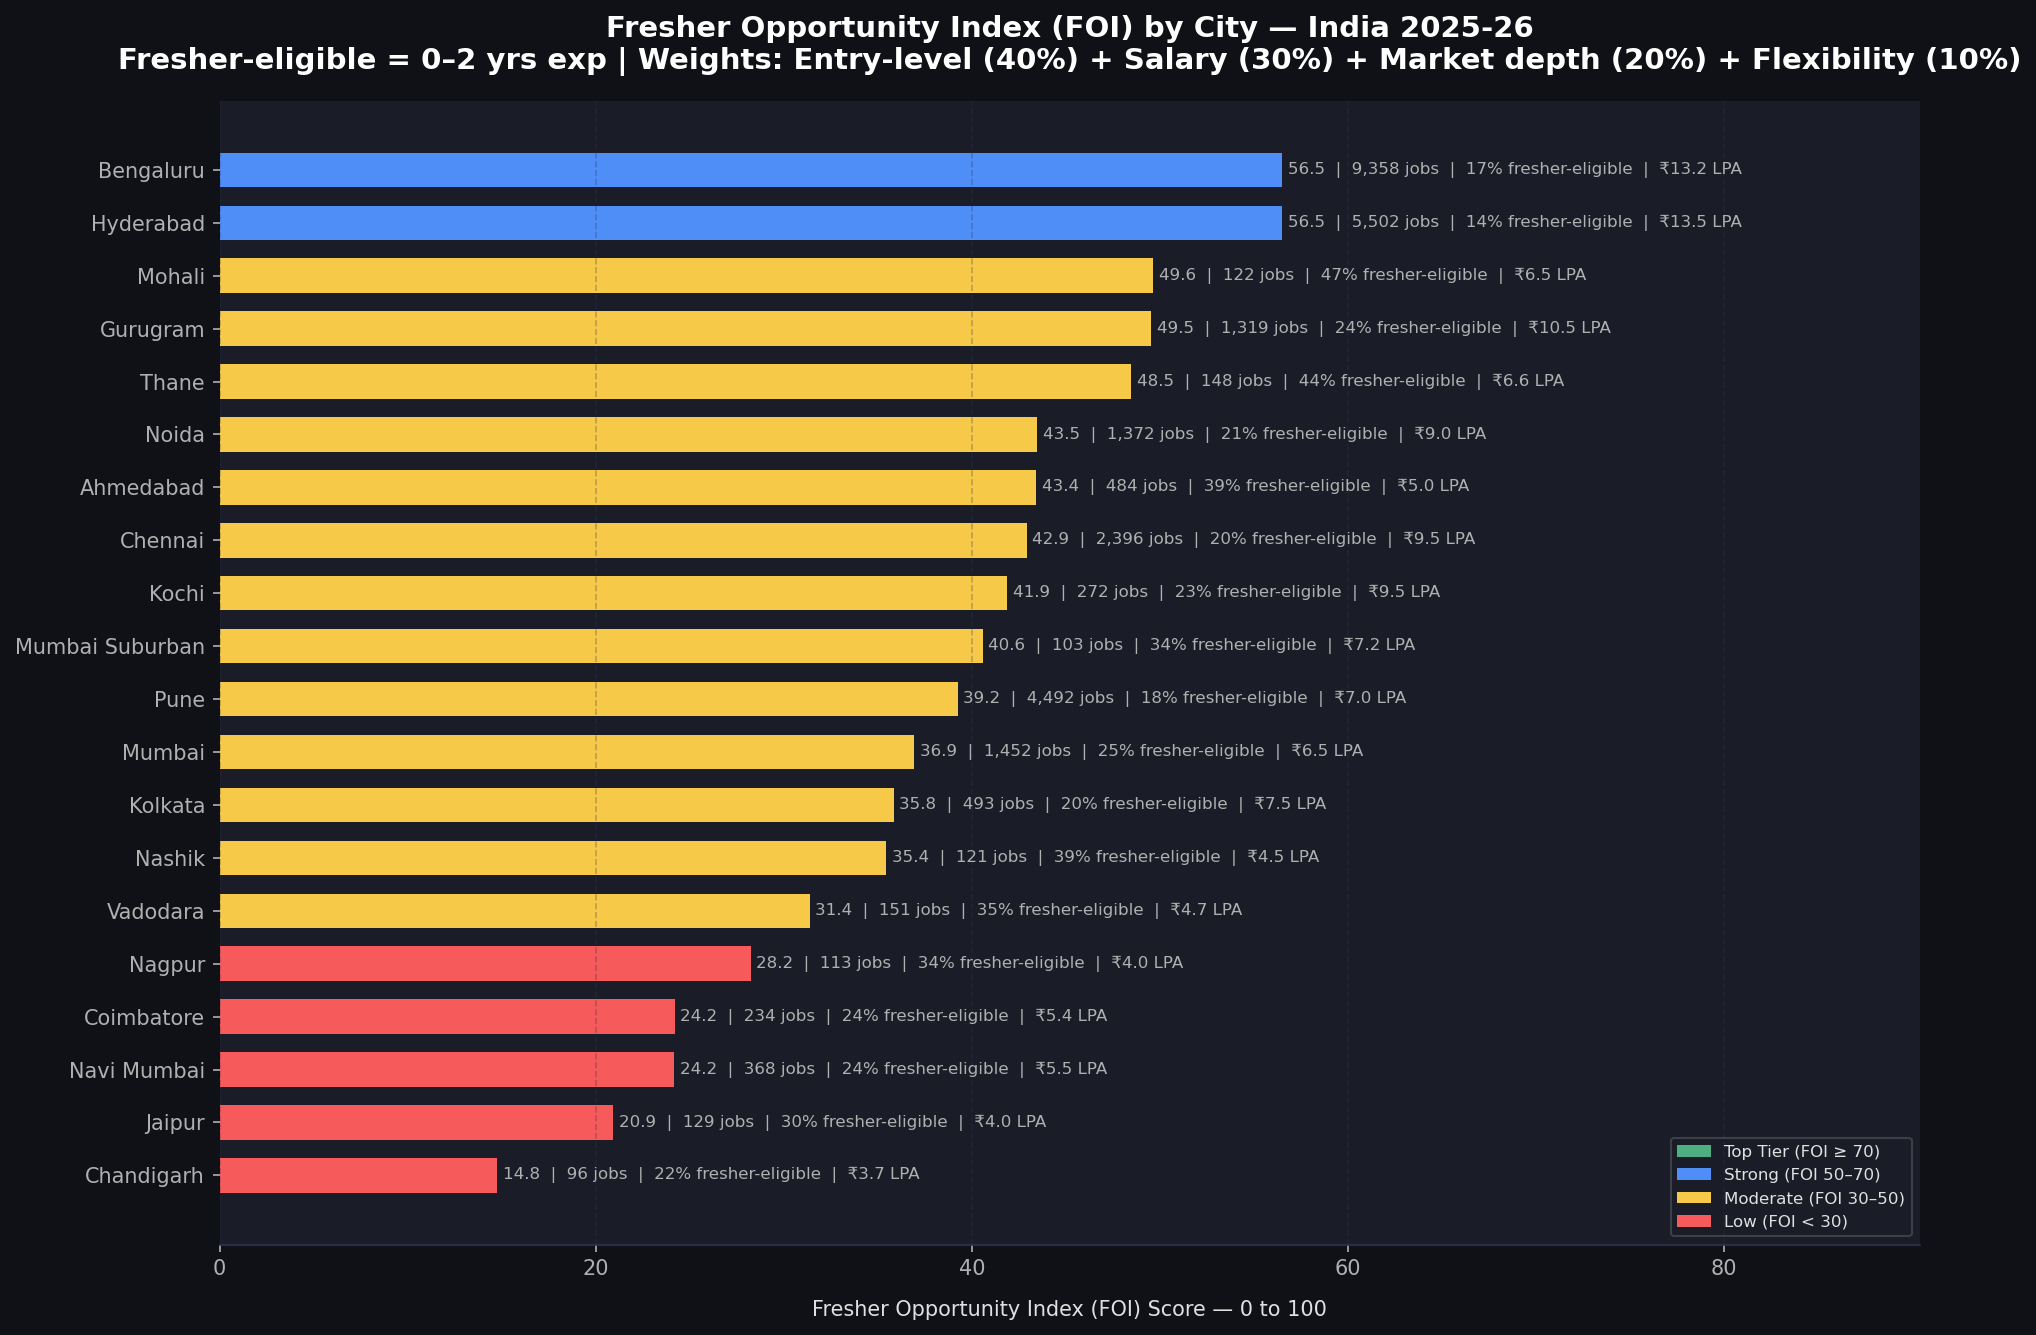

✅ Saved: outputs/charts/C3_fresher_opportunity_index.png

✅ FOI table saved to outputs/tables/city_foi_scores.csv


In [26]:
# ── Chart C3 v2: FOI with corrected fresher definition ───────
foi_plot = foi_v2.sort_values('FOI_score', ascending=True).copy()

fig, ax = plt.subplots(figsize=(13, 9))

def foi_color(score):
    if score >= 70:   return '#4CAF82'
    elif score >= 50: return '#4F8EF7'
    elif score >= 30: return '#F7C948'
    else:             return '#F75A5A'

bar_colors_foi = [foi_color(s) for s in foi_plot['FOI_score']]

bars = ax.barh(foi_plot['city'],
               foi_plot['FOI_score'],
               color=bar_colors_foi,
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, foi_plot.itertuples()):
    lpa = f"₹{row.city_median_lpa:.1f} LPA" if row.city_median_lpa else "salary N/A"
    label = (f'{row.FOI_score:.1f}  |  {row.total_postings:,} jobs  '
             f'|  {row.fresher_ratio:.0f}% fresher-eligible  |  {lpa}')
    ax.text(bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            label,
            va='center', ha='left', fontsize=8, color=COLORS['subtext'])

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF82', label='Top Tier (FOI ≥ 70)'),
    Patch(facecolor='#4F8EF7', label='Strong (FOI 50–70)'),
    Patch(facecolor='#F7C948', label='Moderate (FOI 30–50)'),
    Patch(facecolor='#F75A5A', label='Low (FOI < 30)')
]
ax.legend(handles=legend_elements, loc='lower right',
          framealpha=0.2, fontsize=8)

ax.set_xlabel('Fresher Opportunity Index (FOI) Score — 0 to 100', labelpad=10)
ax.set_title('Fresher Opportunity Index (FOI) by City — India 2025-26\n'
             'Fresher-eligible = 0–2 yrs exp | Weights: Entry-level (40%) + '
             'Salary (30%) + Market depth (20%) + Flexibility (10%)',
             pad=15)
ax.set_xlim(0, foi_plot['FOI_score'].max() * 1.6)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('C3_fresher_opportunity_index.png')

# Save final FOI table
foi_v2.to_csv('outputs/tables/city_foi_scores.csv', index=False)
print(f"\n✅ FOI table saved to outputs/tables/city_foi_scores.csv")

In [28]:
# Persist the corrected fresher flag
df_tech['fresher_eligible'] = df_tech['minimumExperience'] <= 2

# Update the processed file with this new column
df_tech.to_csv('data/processed/tech_jobs_cleaned.csv', index=False)
print(f"✅ tech_jobs_cleaned.csv updated with fresher_eligible column")
print(f"   Shape: {df_tech.shape}")

✅ tech_jobs_cleaned.csv updated with fresher_eligible column
   Shape: (32438, 28)


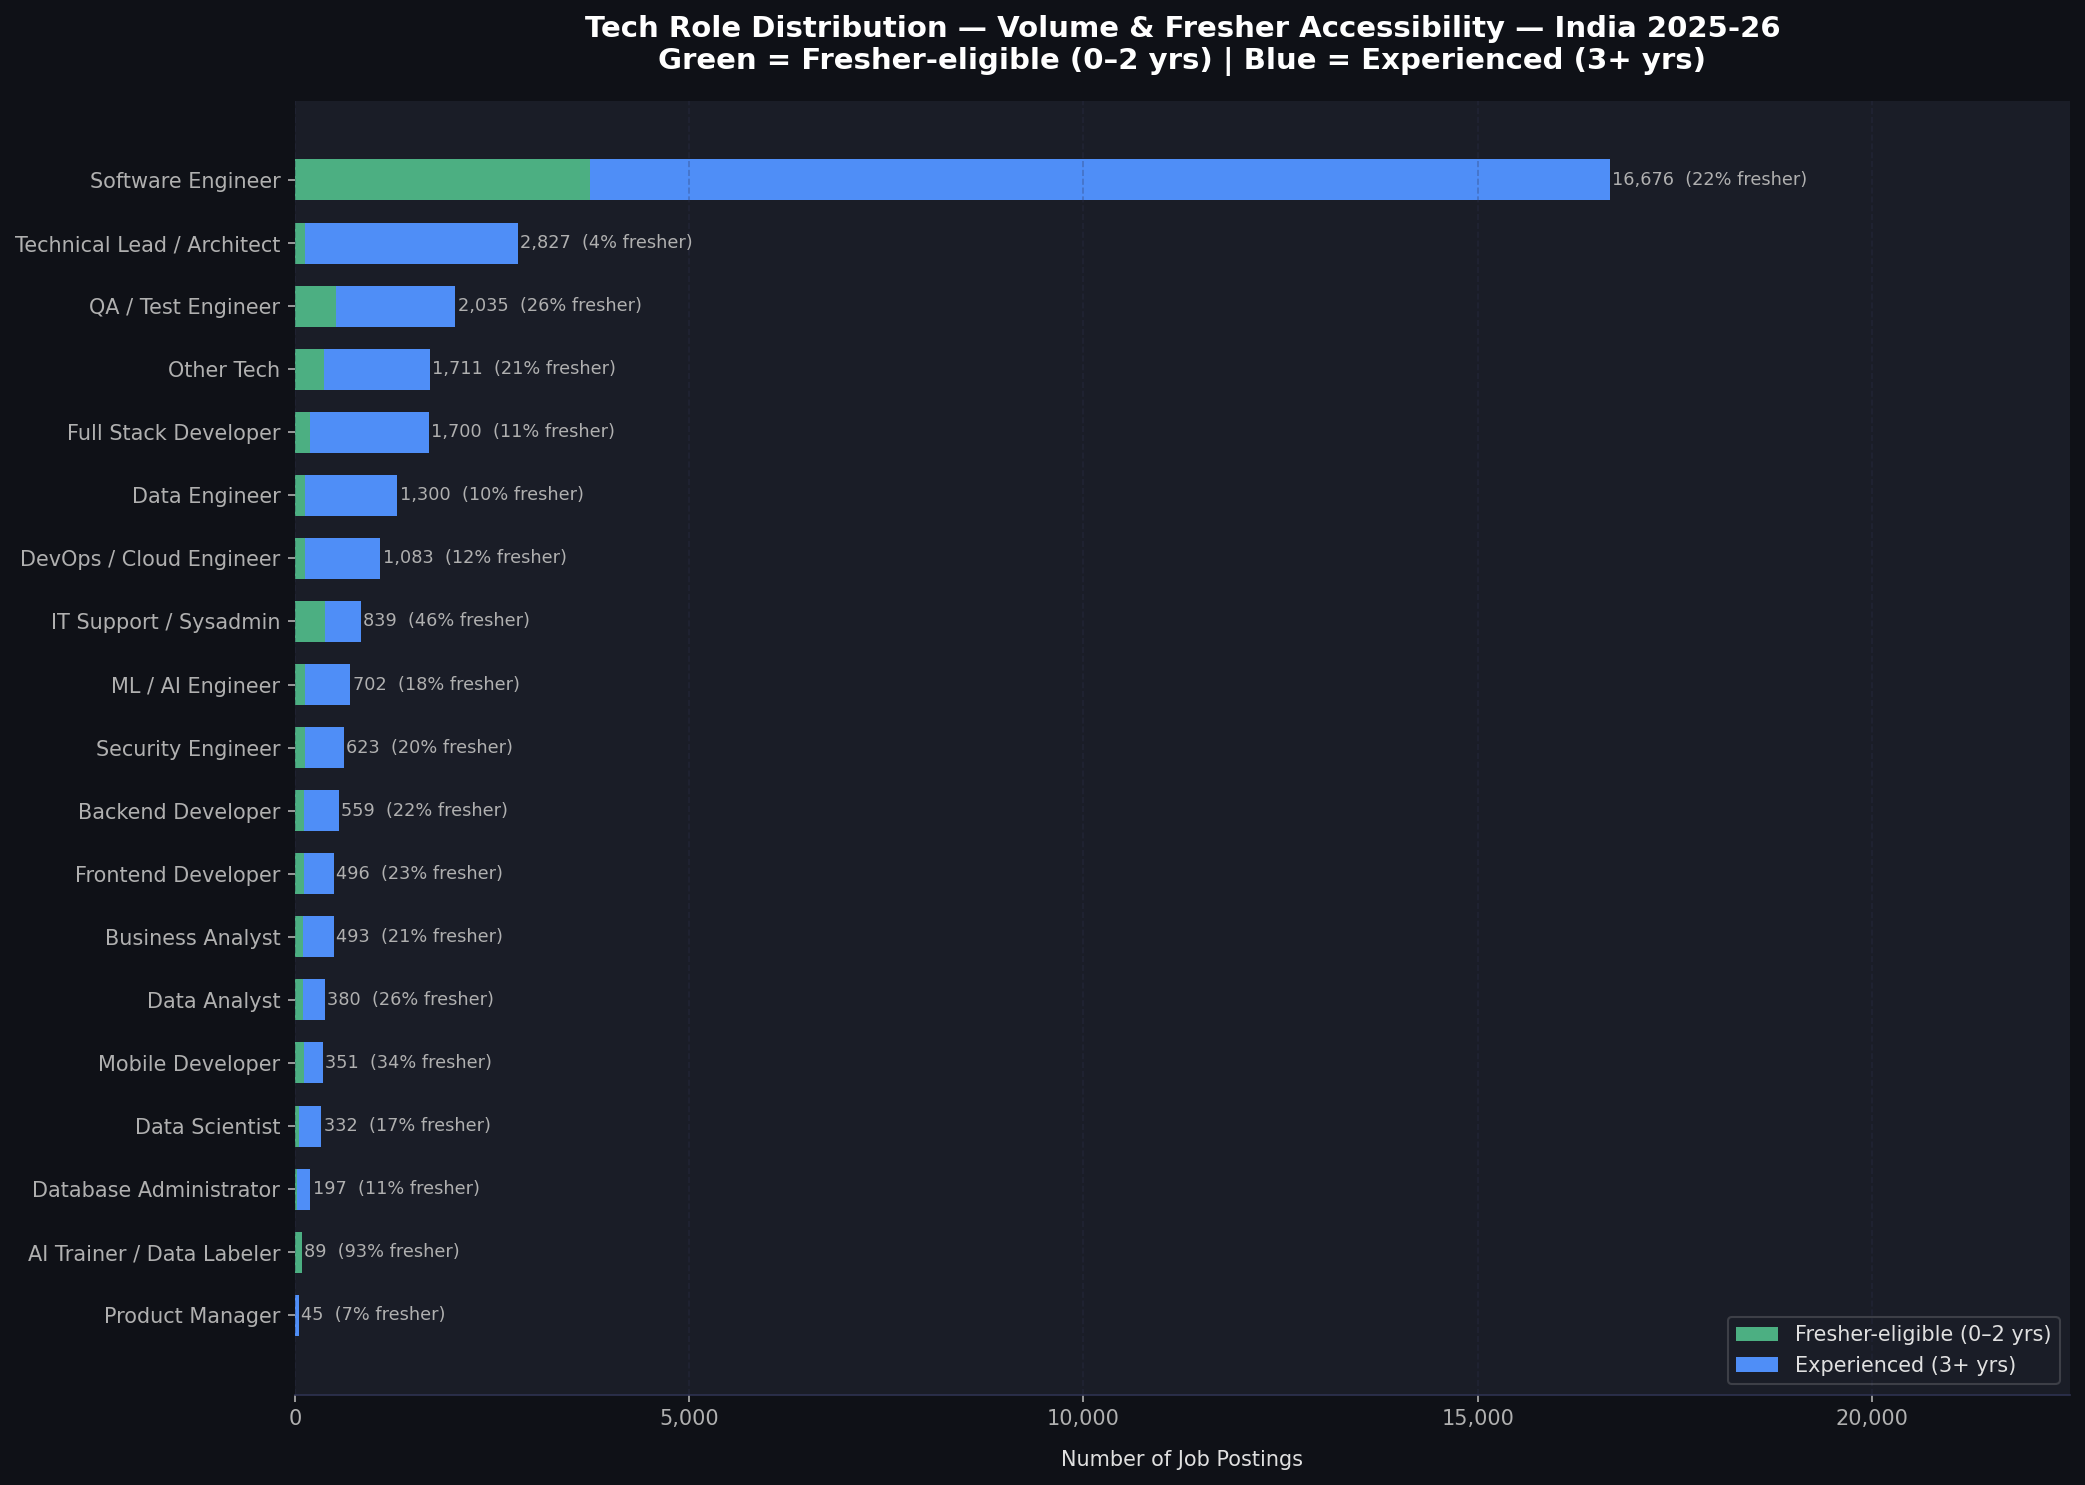

✅ Saved: outputs/charts/D1_role_volume_fresher_split.png


In [29]:
# ── BLOCK D: ROLE INTELLIGENCE ───────────────────────────────

# ── Chart D1: Tech Role Distribution — Volume + Fresher Split ─
role_stats = (df_tech.groupby('role_category')
              .agg(
                  total=('jobId', 'count'),
                  fresher_eligible=('fresher_eligible', 'sum')
              )
              .reset_index())

role_stats['fresher_pct'] = (role_stats['fresher_eligible'] / 
                              role_stats['total'] * 100).round(1)
role_stats['senior_count'] = role_stats['total'] - role_stats['fresher_eligible']
role_stats = role_stats.sort_values('total', ascending=True)

fig, ax = plt.subplots(figsize=(14, 10))

# Stacked bar: fresher-eligible vs senior
bars1 = ax.barh(role_stats['role_category'],
                role_stats['fresher_eligible'],
                color=COLORS['green'],
                edgecolor='none',
                height=0.65,
                label='Fresher-eligible (0–2 yrs)')

bars2 = ax.barh(role_stats['role_category'],
                role_stats['senior_count'],
                left=role_stats['fresher_eligible'],
                color=COLORS['primary'],
                edgecolor='none',
                height=0.65,
                label='Experienced (3+ yrs)')

# Labels showing total + fresher %
for _, row in role_stats.iterrows():
    ax.text(row['total'] + 30,
            list(role_stats['role_category']).index(row['role_category']),
            f"{row['total']:,}  ({row['fresher_pct']:.0f}% fresher)",
            va='center', ha='left', fontsize=8.5, color=COLORS['subtext'])

ax.set_xlabel('Number of Job Postings', labelpad=10)
ax.set_title('Tech Role Distribution — Volume & Fresher Accessibility — India 2025-26\n'
             'Green = Fresher-eligible (0–2 yrs) | Blue = Experienced (3+ yrs)',
             pad=15)
ax.set_xlim(0, role_stats['total'].max() * 1.35)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend(loc='lower right', framealpha=0.2)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('D1_role_volume_fresher_split.png')

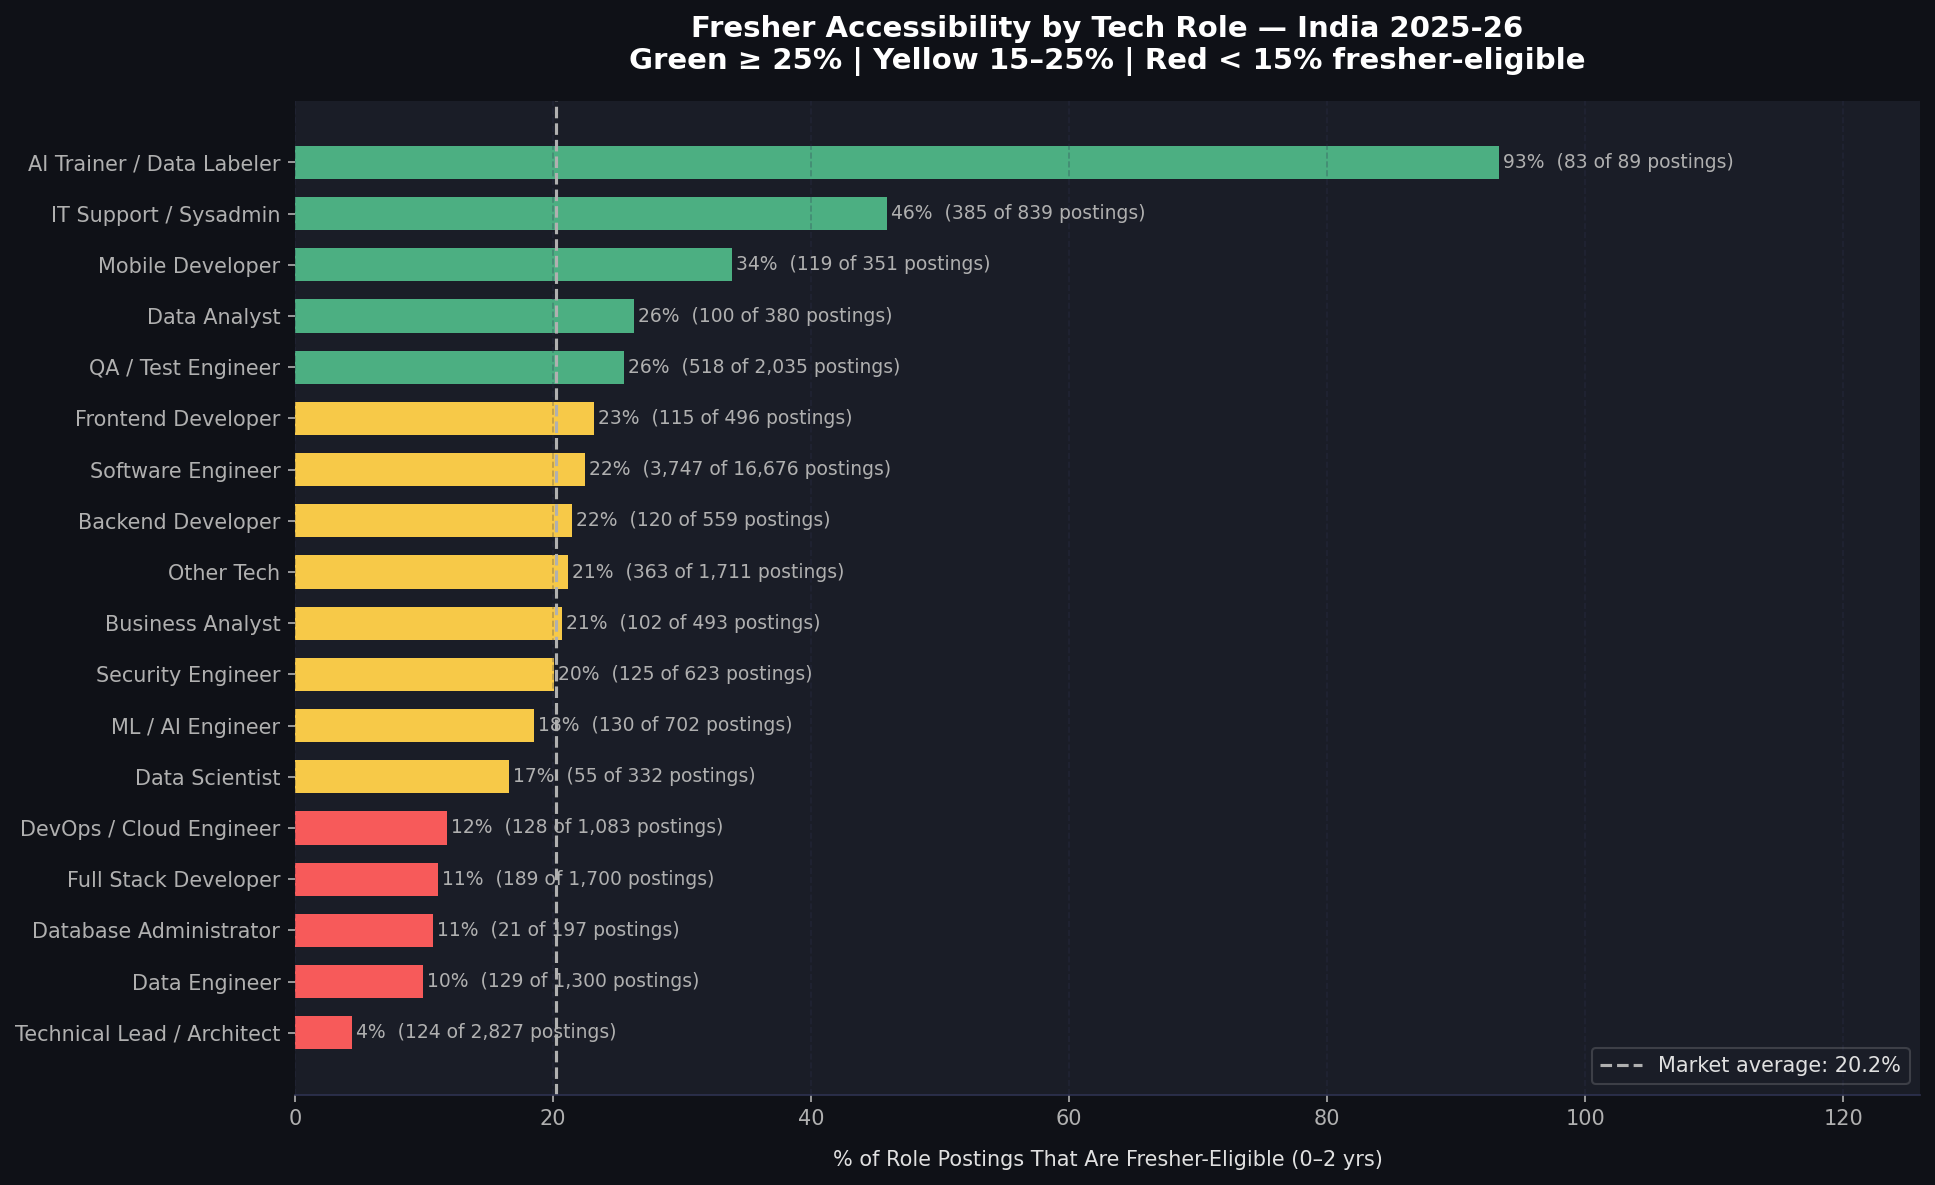

✅ Saved: outputs/charts/D2_role_fresher_accessibility.png


In [30]:
# ── Chart D2: Fresher Accessibility Score by Role ────────────
# Which roles are most accessible to freshers by % of postings?

role_access = (role_stats[role_stats['total'] >= 50]
               .sort_values('fresher_pct', ascending=True)
               .copy())

fig, ax = plt.subplots(figsize=(13, 8))

bar_colors_d2 = [COLORS['green'] if p >= 25
                 else COLORS['secondary'] if p >= 15
                 else COLORS['accent']
                 for p in role_access['fresher_pct']]

bars = ax.barh(role_access['role_category'],
               role_access['fresher_pct'],
               color=bar_colors_d2,
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, role_access.itertuples()):
    ax.text(bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            f'{row.fresher_pct:.0f}%  ({row.fresher_eligible:,} of {row.total:,} postings)',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.axvline(20.21, color=COLORS['subtext'],
           linestyle='--', linewidth=1.5,
           label=f'Market average: 20.2%')

ax.set_xlabel('% of Role Postings That Are Fresher-Eligible (0–2 yrs)', labelpad=10)
ax.set_title('Fresher Accessibility by Tech Role — India 2025-26\n'
             'Green ≥ 25% | Yellow 15–25% | Red < 15% fresher-eligible',
             pad=15)
ax.set_xlim(0, role_access['fresher_pct'].max() * 1.35)
ax.legend(loc='lower right', framealpha=0.2)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('D2_role_fresher_accessibility.png')

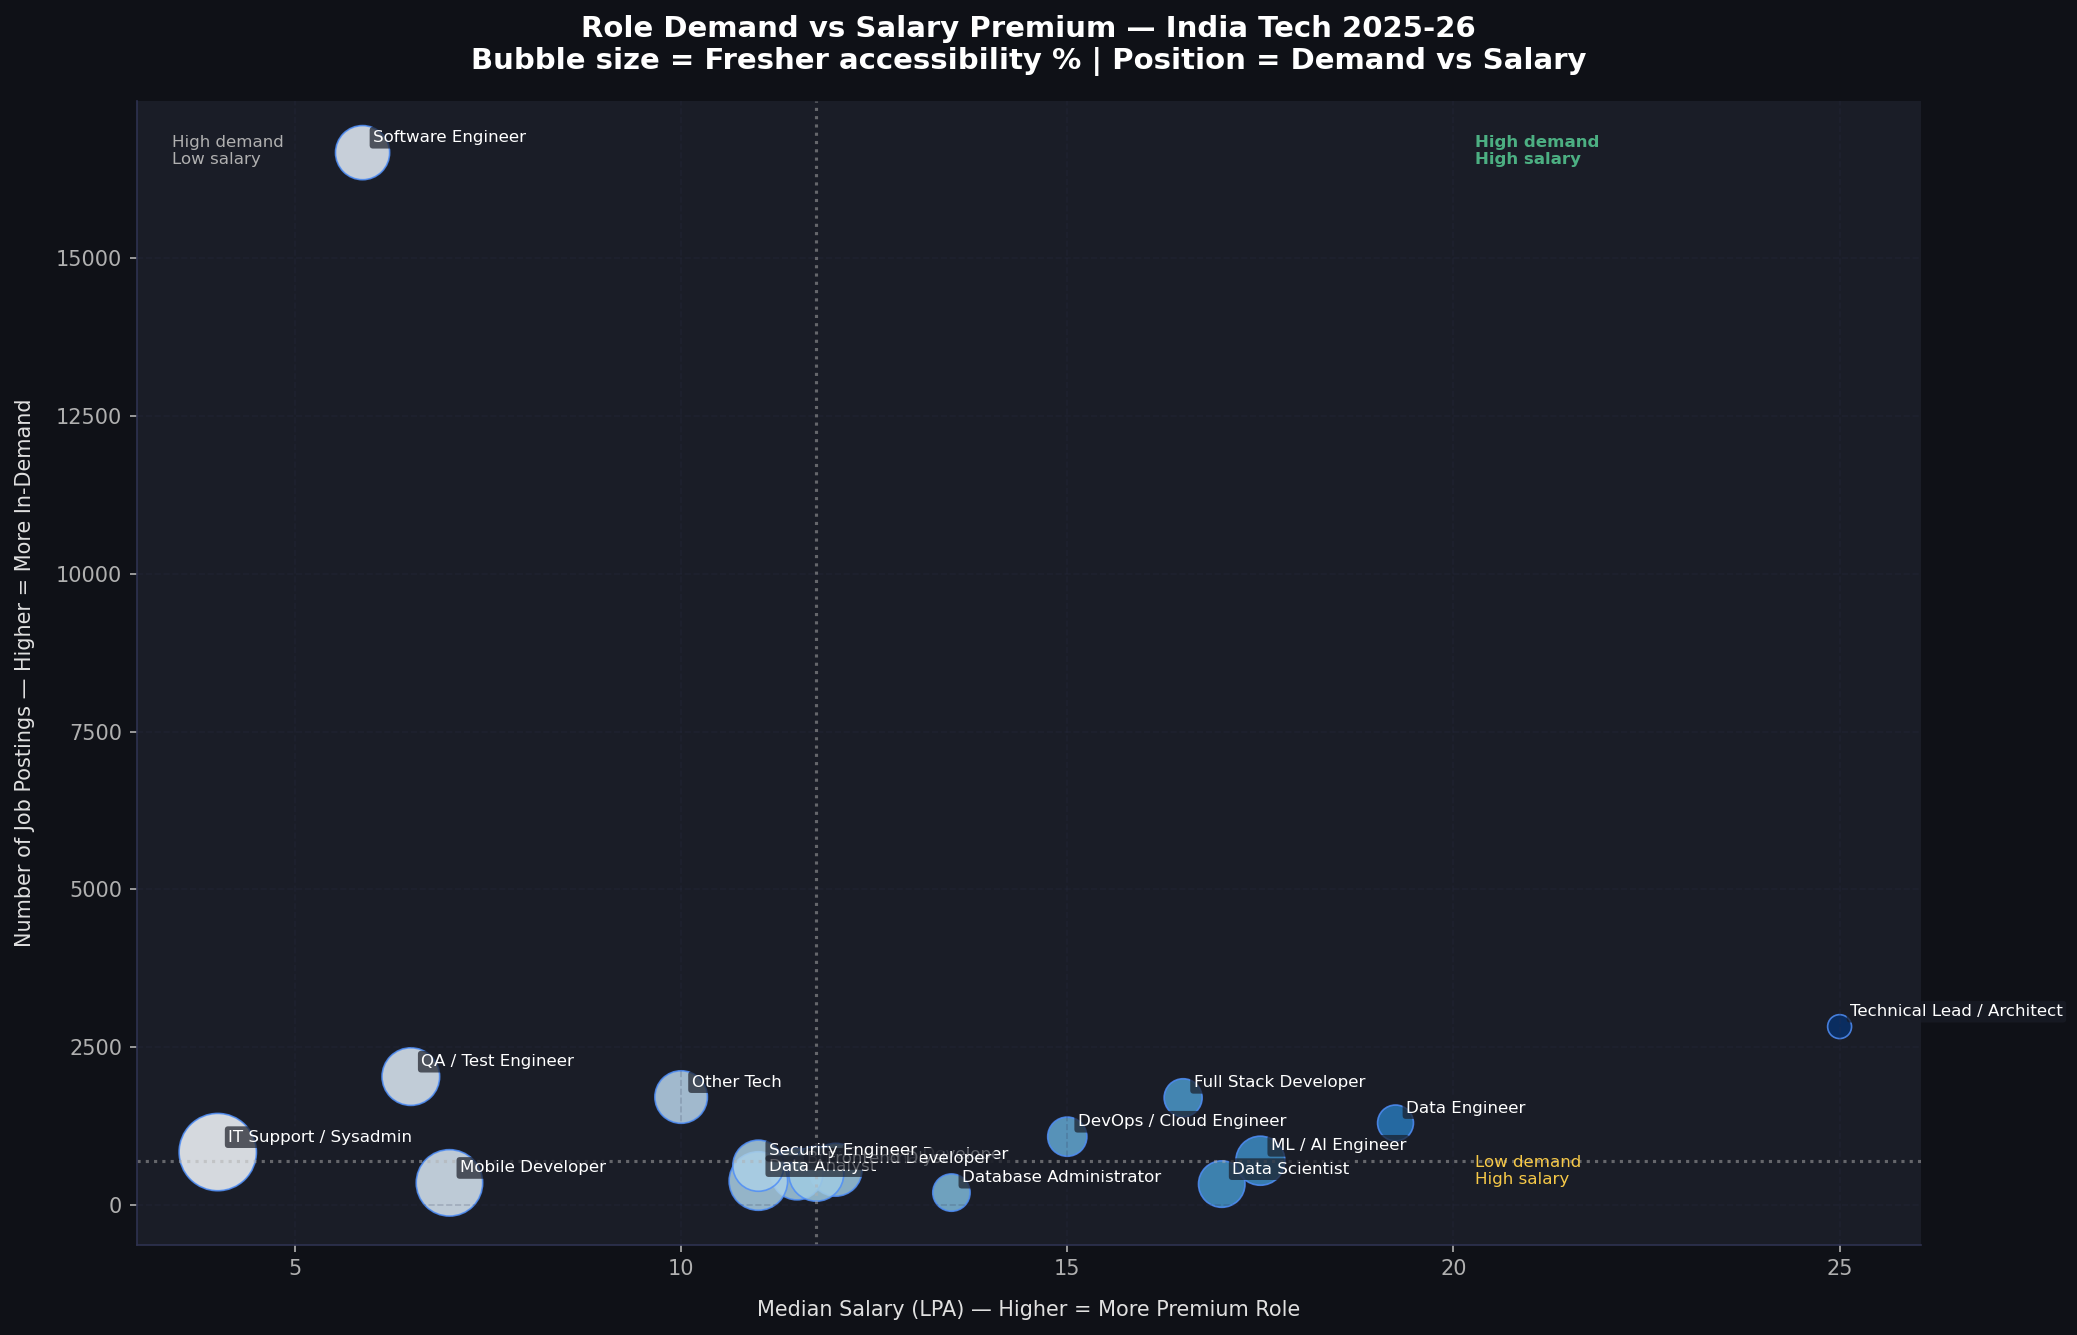

✅ Saved: outputs/charts/D3_role_demand_vs_salary_bubble.png


In [31]:
# ── Chart D3: Salary vs Demand Bubble Chart ──────────────────
# Business Question 21: Which roles are growing fastest?
# Proxy: volume = current demand, salary = premium signal

role_bubble = (df_tech.groupby('role_category')
               .agg(total=('jobId', 'count'))
               .reset_index()
               .merge(
                   df_salary.groupby('role_category')['salary_lpa']
                   .median().reset_index()
                   .rename(columns={'salary_lpa': 'median_salary'}),
                   on='role_category', how='left'
               )
               .merge(
                   role_stats[['role_category', 'fresher_pct']],
                   on='role_category'
               )
               .dropna(subset=['median_salary'])
               .query('total >= 50'))

fig, ax = plt.subplots(figsize=(14, 9))

scatter = ax.scatter(role_bubble['median_salary'],
                     role_bubble['total'],
                     s=role_bubble['fresher_pct'] * 30,
                     c=role_bubble['median_salary'],
                      cmap='Blues',
                     alpha=0.85,
                     edgecolors=COLORS['primary'],
                     linewidth=0.8)

for _, row in role_bubble.iterrows():
    ax.annotate(row['role_category'],
                xy=(row['median_salary'], row['total']),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8, color=COLORS['text'],
                bbox=dict(boxstyle='round,pad=0.2',
                          facecolor='#1A1D27',
                          edgecolor='none',
                          alpha=0.7))

ax.set_xlabel('Median Salary (LPA) — Higher = More Premium Role', labelpad=10)
ax.set_ylabel('Number of Job Postings — Higher = More In-Demand', labelpad=10)
ax.set_title('Role Demand vs Salary Premium — India Tech 2025-26\n'
             'Bubble size = Fresher accessibility % | Position = Demand vs Salary',
             pad=15)
ax.grid(alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)

# Quadrant lines at medians
ax.axvline(role_bubble['median_salary'].median(),
           color=COLORS['subtext'], linestyle=':', alpha=0.5)
ax.axhline(role_bubble['total'].median(),
           color=COLORS['subtext'], linestyle=':', alpha=0.5)

# Quadrant labels
ax.text(0.02, 0.97, 'High demand\nLow salary',
        transform=ax.transAxes, fontsize=8,
        color=COLORS['subtext'], va='top')
ax.text(0.75, 0.97, 'High demand\nHigh salary',
        transform=ax.transAxes, fontsize=8,
        color=COLORS['green'], va='top', fontweight='bold')
ax.text(0.75, 0.05, 'Low demand\nHigh salary',
        transform=ax.transAxes, fontsize=8,
        color=COLORS['secondary'], va='bottom')

plt.tight_layout()
save_chart('D3_role_demand_vs_salary_bubble.png')

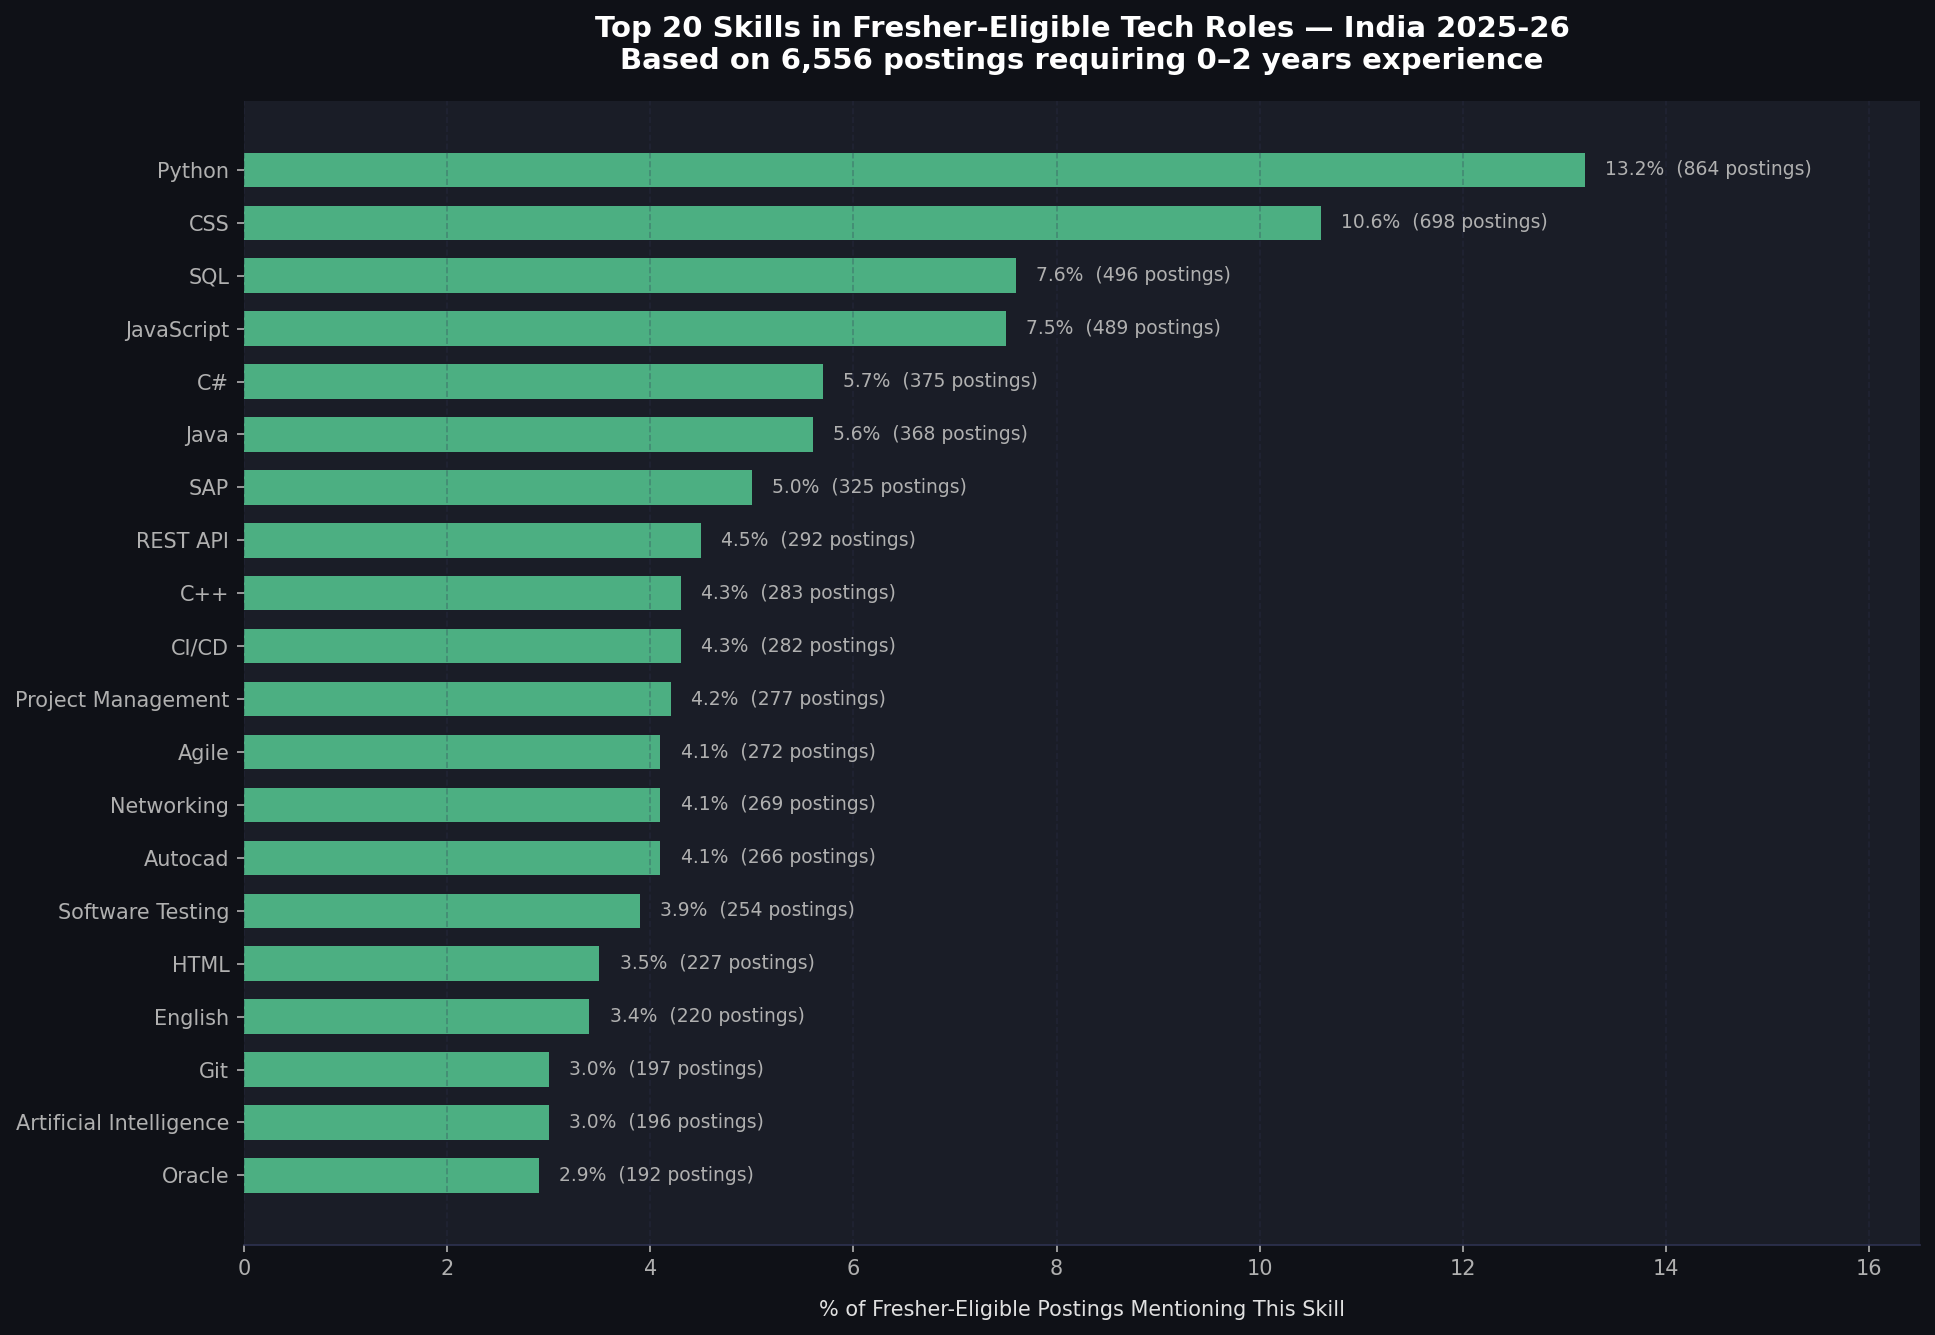

✅ Saved: outputs/charts/D4_fresher_role_skills.png
TOP 20 SKILLS FOR FRESHER-ELIGIBLE ROLES:
                  skill  count  pct
                 Python    864 13.2
                    CSS    698 10.6
                    SQL    496  7.6
             JavaScript    489  7.5
                     C#    375  5.7
                   Java    368  5.6
                    SAP    325  5.0
               REST API    292  4.5
                    C++    283  4.3
                  CI/CD    282  4.3
     Project Management    277  4.2
                  Agile    272  4.1
             Networking    269  4.1
                Autocad    266  4.1
       Software Testing    254  3.9
                   HTML    227  3.5
                English    220  3.4
                    Git    197  3.0
Artificial Intelligence    196  3.0
                 Oracle    192  2.9


In [32]:
# ── Chart D4: Top Skills for Fresher-Eligible Roles ──────────
# What skills should freshers actually prioritize?

fresher_jobs = df_tech[df_tech['fresher_eligible'] == True]['jobId'].unique()

fresher_skills = (df_skills[df_skills['jobId'].isin(fresher_jobs)]
                  ['skill']
                  .value_counts()
                  .head(20)
                  .reset_index())
fresher_skills.columns = ['skill', 'count']
fresher_skills['pct'] = (fresher_skills['count'] /
                          len(fresher_jobs) * 100).round(1)

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(fresher_skills['skill'][::-1],
               fresher_skills['pct'][::-1],
               color=COLORS['green'],
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, fresher_skills[::-1].itertuples()):
    ax.text(bar.get_width() + 0.2,
            bar.get_y() + bar.get_height()/2,
            f'{row.pct}%  ({row.count:,} postings)',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.set_xlabel('% of Fresher-Eligible Postings Mentioning This Skill', labelpad=10)
ax.set_title('Top 20 Skills in Fresher-Eligible Tech Roles — India 2025-26\n'
             f'Based on {len(fresher_jobs):,} postings requiring 0–2 years experience',
             pad=15)
ax.set_xlim(0, fresher_skills['pct'].max() * 1.25)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('D4_fresher_role_skills.png')

# Print the fresher skill list
print("TOP 20 SKILLS FOR FRESHER-ELIGIBLE ROLES:")
print(fresher_skills.to_string(index=False))

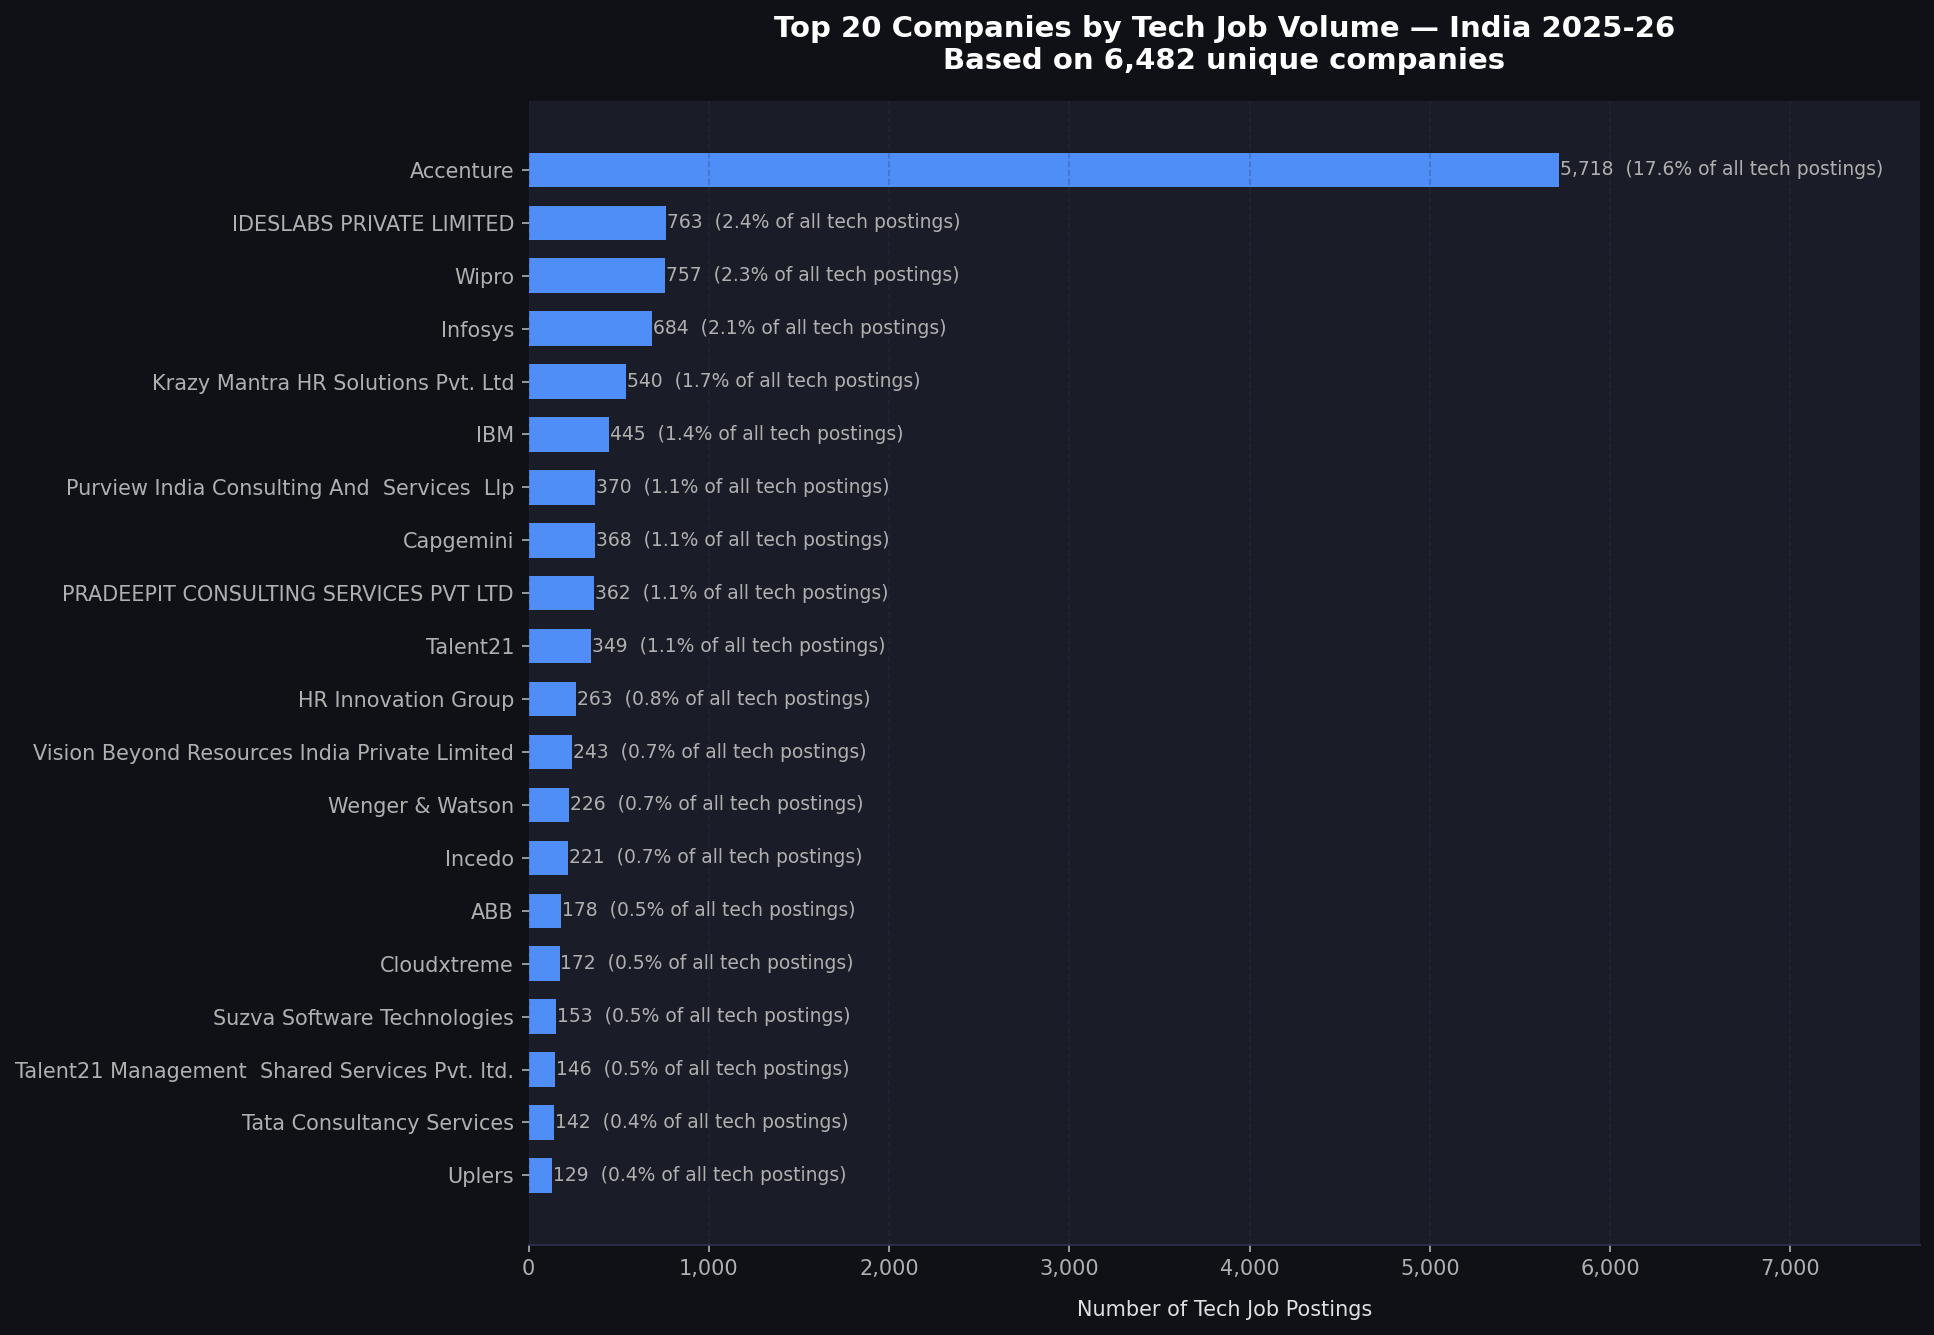

✅ Saved: outputs/charts/E1_top_companies_volume.png


In [33]:
# ── BLOCK E: COMPANY INTELLIGENCE ────────────────────────────

# ── Chart E1: Top 20 Companies by Tech Job Volume ────────────
top_companies = (df_tech.groupby('companyName')
                 .size()
                 .reset_index(name='job_count')
                 .sort_values('job_count', ascending=False)
                 .head(20)
                 .sort_values('job_count', ascending=True))

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(top_companies['companyName'],
               top_companies['job_count'],
               color=COLORS['primary'],
               edgecolor='none',
               height=0.65)

for bar, val in zip(bars, top_companies['job_count']):
    pct = val / len(df_tech) * 100
    ax.text(bar.get_width() + 5,
            bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({pct:.1f}% of all tech postings)',
            va='center', ha='left', fontsize=9, color=COLORS['subtext'])

ax.set_xlabel('Number of Tech Job Postings', labelpad=10)
ax.set_title('Top 20 Companies by Tech Job Volume — India 2025-26\n'
             f'Based on {df_tech["companyName"].nunique():,} unique companies',
             pad=15)

ax.set_xlim(0, top_companies['job_count'].max() * 1.35)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('E1_top_companies_volume.png')

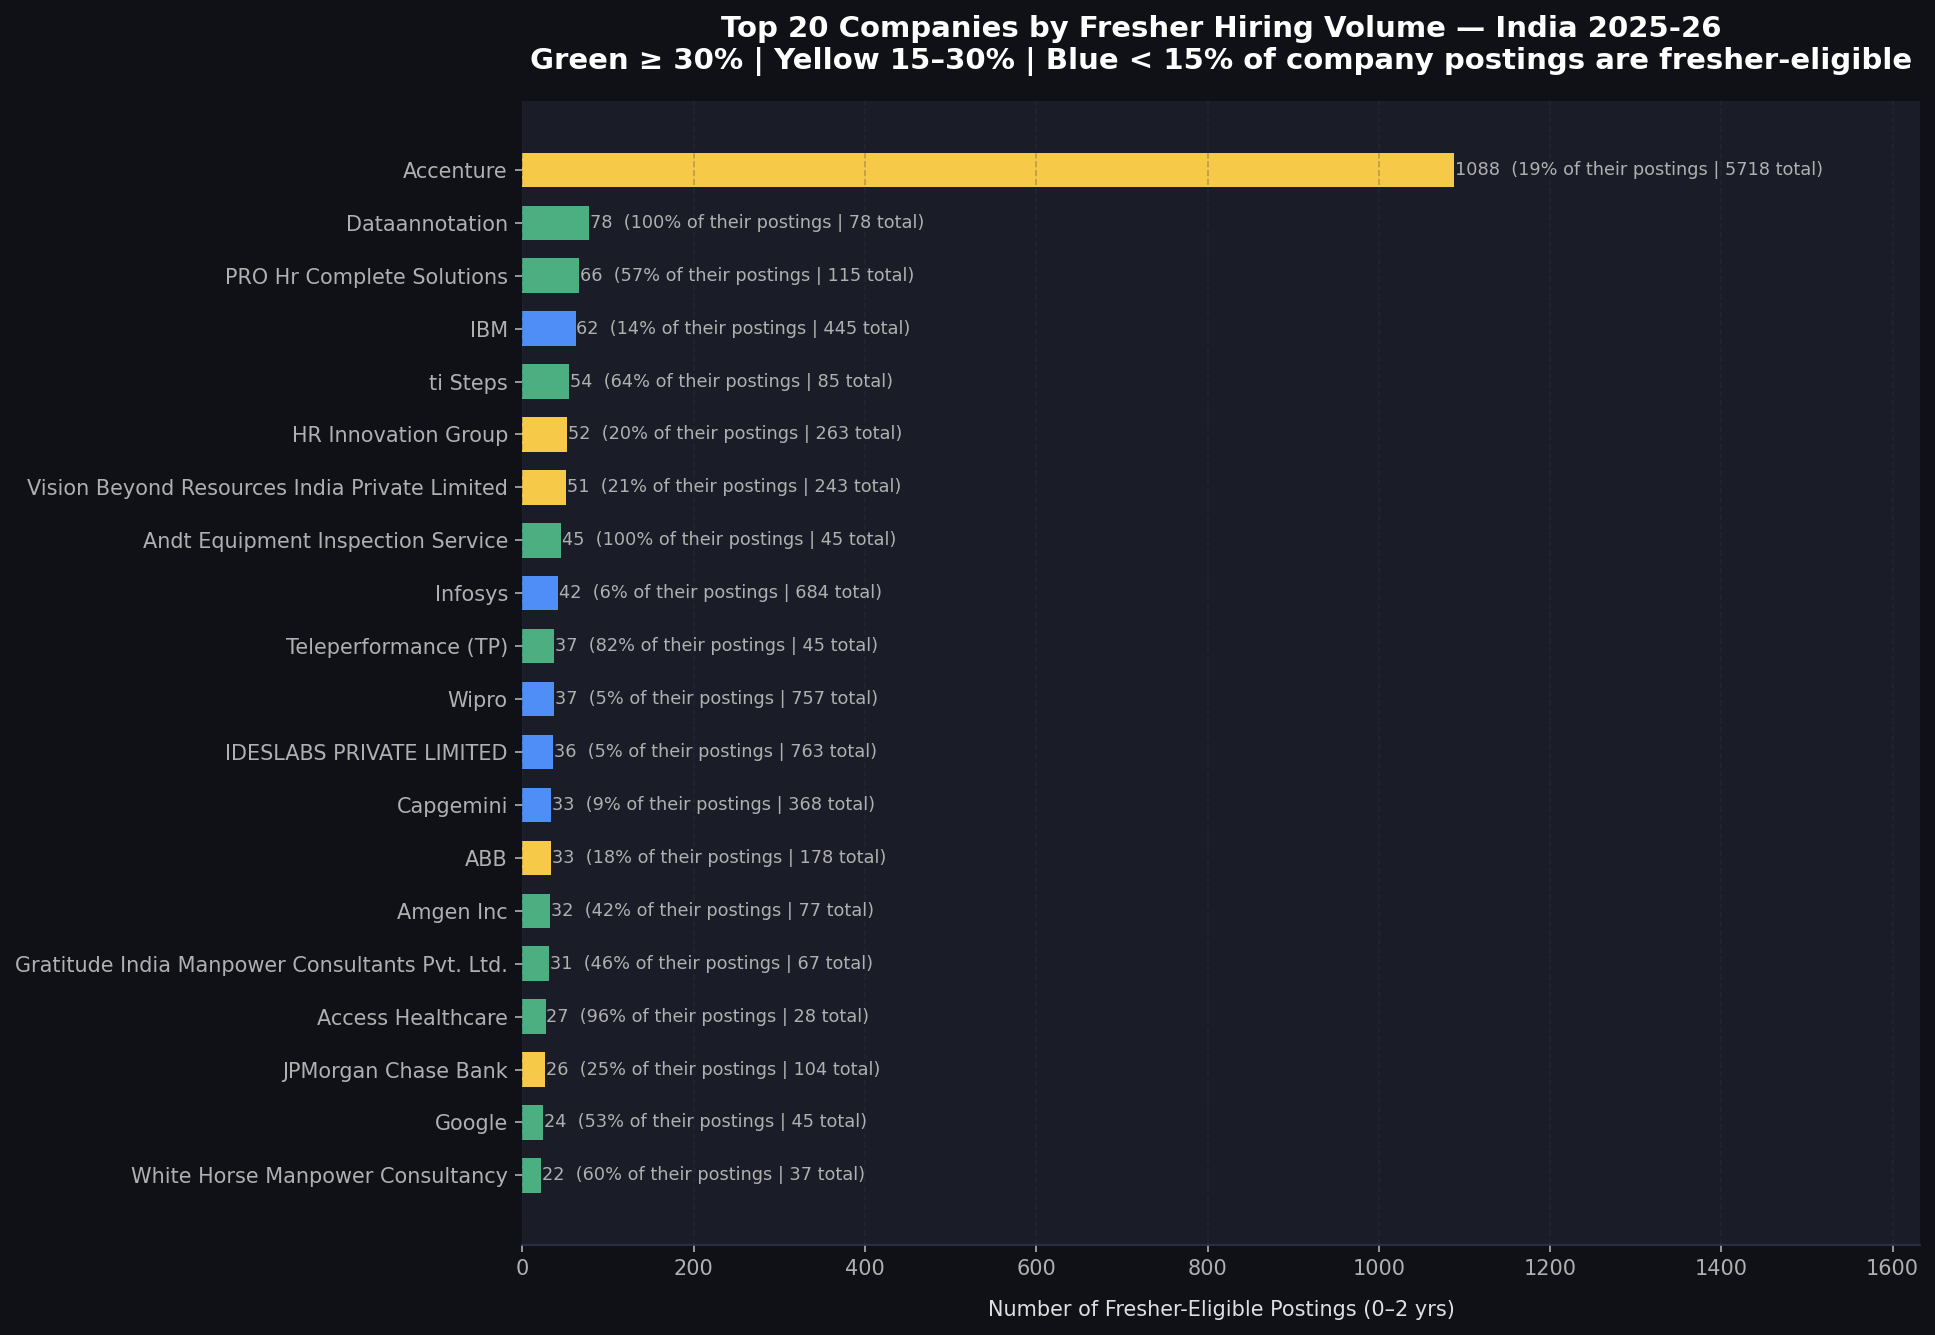

✅ Saved: outputs/charts/E2_top_fresher_companies.png


In [34]:
# ── Chart E2: Top Companies for Fresher Hiring ───────────────
company_fresher = (df_tech.groupby('companyName')
                   .agg(
                       total=('jobId', 'count'),
                       fresher_count=('fresher_eligible', 'sum')
                   )
                   .reset_index())

company_fresher['fresher_pct'] = (company_fresher['fresher_count'] /
                                   company_fresher['total'] * 100).round(1)

# Companies with at least 10 total postings
company_fresher = company_fresher[company_fresher['total'] >= 10].copy()

# Top 20 by absolute fresher count
top_fresher_companies = (company_fresher
                         .sort_values('fresher_count', ascending=False)
                         .head(20)
                         .sort_values('fresher_count', ascending=True))

fig, ax = plt.subplots(figsize=(13, 9))

bar_colors_e2 = [COLORS['green'] if p >= 30
                 else COLORS['secondary'] if p >= 15
                  else COLORS['primary']
                 for p in top_fresher_companies['fresher_pct']]

bars = ax.barh(top_fresher_companies['companyName'],
               top_fresher_companies['fresher_count'],
               color=bar_colors_e2,
               edgecolor='none',
               height=0.65)

for bar, row in zip(bars, top_fresher_companies.itertuples()):
    ax.text(bar.get_width() + 1,
            bar.get_y() + bar.get_height()/2,
            f'{row.fresher_count}  ({row.fresher_pct:.0f}% of their postings | {row.total} total)',
            va='center', ha='left', fontsize=8.5, color=COLORS['subtext'])

ax.set_xlabel('Number of Fresher-Eligible Postings (0–2 yrs)', labelpad=10)
ax.set_title('Top 20 Companies by Fresher Hiring Volume — India 2025-26\n'
             'Green ≥ 30% | Yellow 15–30% | Blue < 15% of company postings are fresher-eligible',
             pad=15)
ax.set_xlim(0, top_fresher_companies['fresher_count'].max() * 1.5)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
save_chart('E2_top_fresher_companies.png')

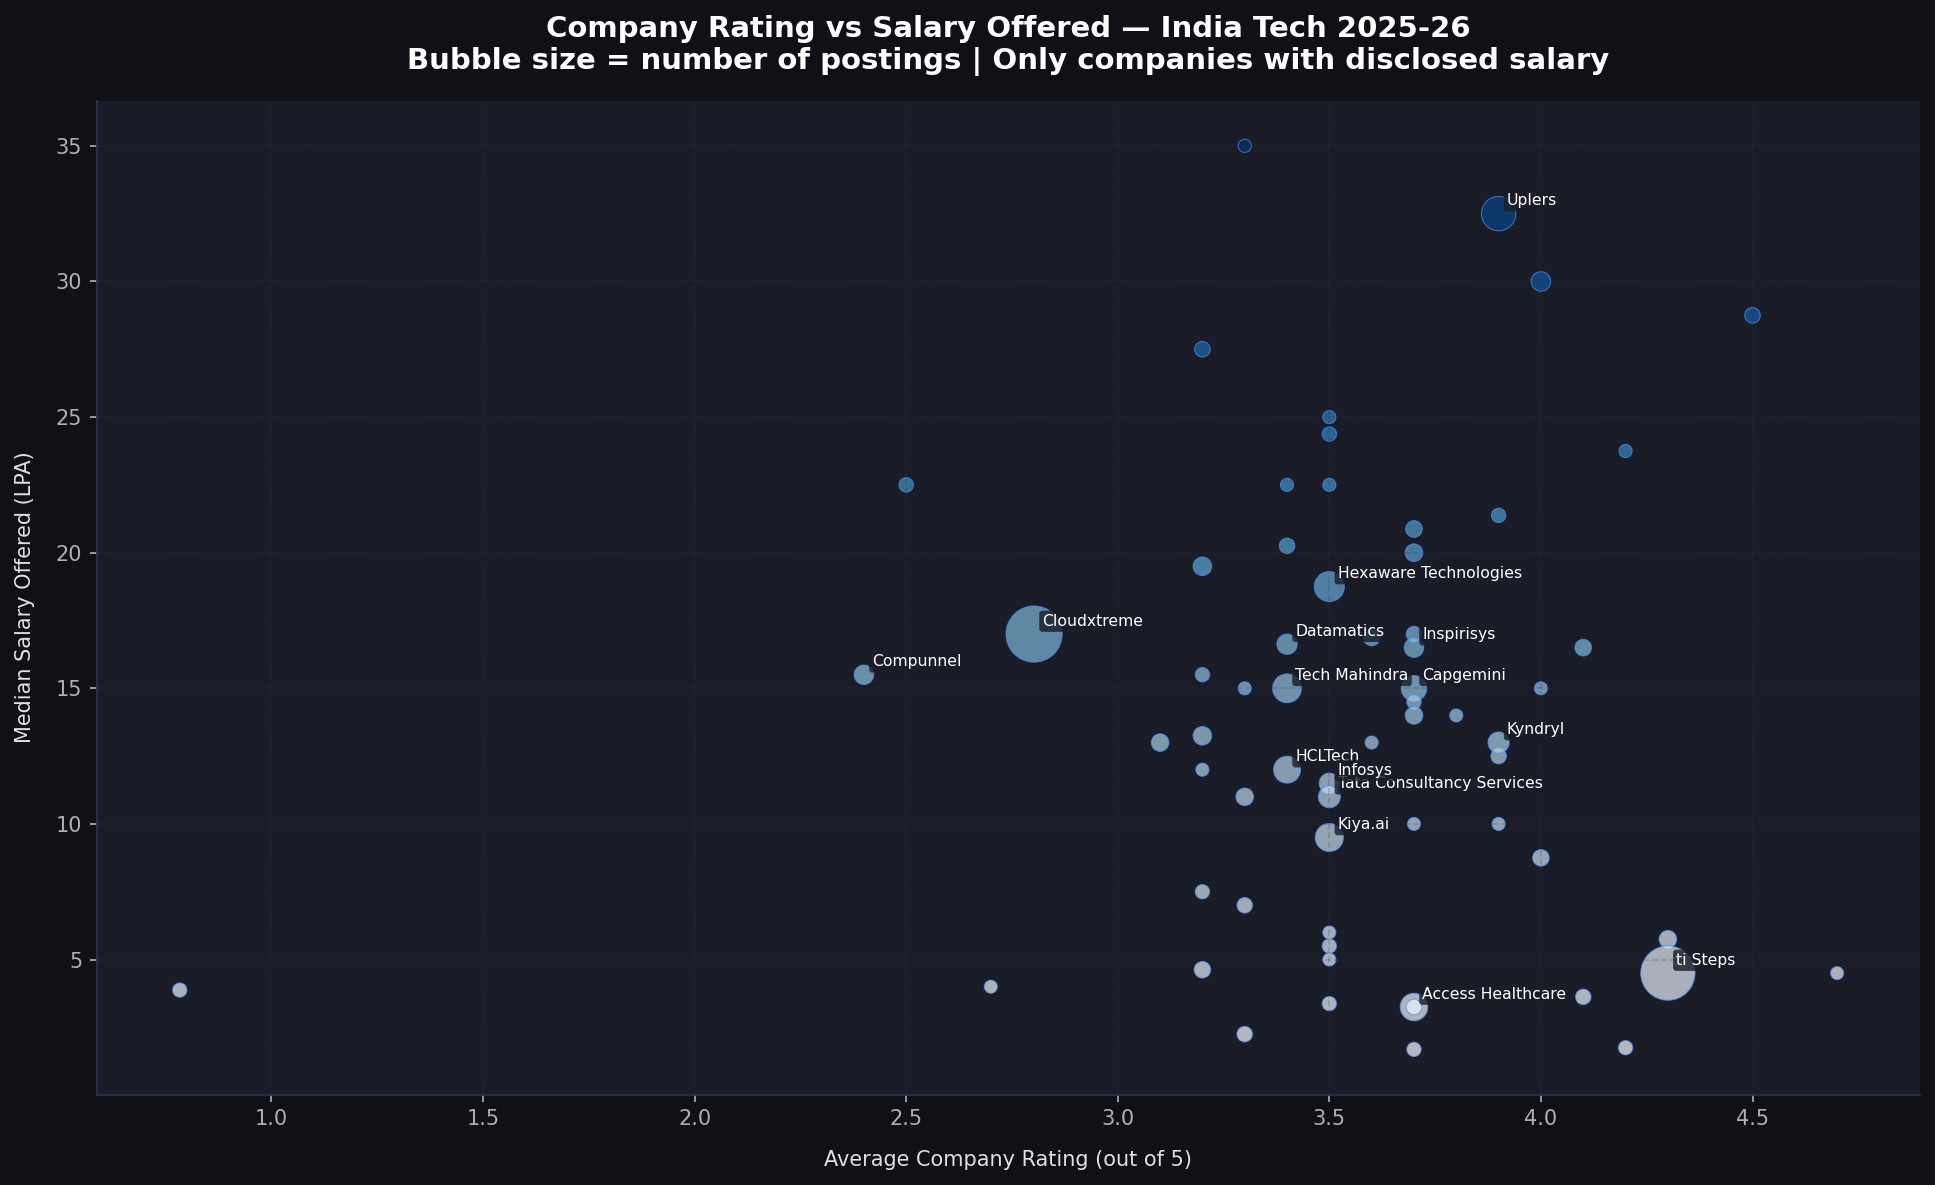

✅ Saved: outputs/charts/E3_company_rating_vs_salary.png

TOP 20 FRESHER-FRIENDLY COMPANIES:
                                   companyName  fresher_count  fresher_pct  total
                                     Accenture           1088         19.0   5718
                                Dataannotation             78        100.0     78
                     PRO Hr Complete Solutions             66         57.4    115
                                           IBM             62         13.9    445
                                      ti Steps             54         63.5     85
                           HR Innovation Group             52         19.8    263
 Vision Beyond Resources India Private Limited             51         21.0    243
             Andt Equipment Inspection Service             45        100.0     45
                                       Infosys             42          6.1    684
                          Teleperformance (TP)             37         82.2     45
      

In [35]:
# ── Chart E3: Company Rating vs Salary (disclosed companies) ──
company_quality = (df_salary.groupby('companyName')
                   .agg(
                       median_salary=('salary_lpa', 'median'),
                       n_postings=('jobId', 'count'),
                       avg_rating=('AggregateRating', 'mean')
                   )
                   .reset_index()
                   .query('n_postings >= 5 and avg_rating > 0'))

fig, ax = plt.subplots(figsize=(13, 8))

scatter = ax.scatter(company_quality['avg_rating'],
                     company_quality['median_salary'],
                     s=company_quality['n_postings'] * 8,
                     c=company_quality['median_salary'],
                     cmap='Blues',
                     alpha=0.7,
                     edgecolors='#4F8EF7',
                     linewidth=0.5)

# Label top 15 companies by posting volume
top15 = company_quality.nlargest(15, 'n_postings')
for _, row in top15.iterrows():
    ax.annotate(row['companyName'],
                xy=(row['avg_rating'], row['median_salary']),
                xytext=(4, 4), textcoords='offset points',
                fontsize=7.5, color=COLORS['text'],
                bbox=dict(boxstyle='round,pad=0.2',
                           facecolor='#1A1D27',
                          edgecolor='none', alpha=0.8))

ax.set_xlabel('Average Company Rating (out of 5)', labelpad=10)
ax.set_ylabel('Median Salary Offered (LPA)', labelpad=10)
ax.set_title('Company Rating vs Salary Offered — India Tech 2025-26\n'
             'Bubble size = number of postings | Only companies with disclosed salary',
             pad=15)
ax.grid(alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
save_chart('E3_company_rating_vs_salary.png')

# Print top fresher companies summary
print("\nTOP 20 FRESHER-FRIENDLY COMPANIES:")
print(top_fresher_companies[['companyName', 'fresher_count',
                              'fresher_pct', 'total']]
      .sort_values('fresher_count', ascending=False)
      .to_string(index=False))